In [1]:
# Download the dataset
# !gdown 1OzKvNaYr5lcCeHpW_1TeNq6Y9nq7cI1l
!gdown 1OzKvNaYr5lcCeHpW_1TeNq6Y9nq7cI1l

Downloading...
From (original): https://drive.google.com/uc?id=1OzKvNaYr5lcCeHpW_1TeNq6Y9nq7cI1l
From (redirected): https://drive.google.com/uc?id=1OzKvNaYr5lcCeHpW_1TeNq6Y9nq7cI1l&confirm=t&uuid=1f7c35bd-eff4-46e0-b5f2-0c6ac0cf14f1
To: /kaggle/working/all-data.csv
100%|████████████████████████████████████████| 297M/297M [00:03<00:00, 93.2MB/s]


In [2]:
#-------------- Import Required Libraries ---------------#

import os
import zipfile
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import tensorflow as tf
from tensorflow.keras.layers import Bidirectional

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report, silhouette_score)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score
)

from scipy.stats import mode
from xgboost import XGBClassifier


2025-10-24 12:41:46.395627: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1761309706.571440      37 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1761309706.627227      37 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
#-------------- Load the Dataset ---------------#

df = pd.read_csv('all-data.csv')
print("Shape of dataset:", df.shape)
df.head()

/tmp/ipykernel_37/3118591543.py:3: DtypeWarning: Columns (85) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('all-data.csv')


Shape of dataset: (630457, 88)


,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label
0,0,192.168.50.7-23.32.166.121-52380-443-6,192.168.50.7,52380,23.32.166.121,443,6,2018-12-01 13:34:28.579374,1,2,...,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,0,BENIGN
1,1,192.168.50.7-23.32.166.121-52380-443-6,23.32.166.121,443,192.168.50.7,52380,6,2018-12-01 13:34:28.605293,2,3,...,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,1,BENIGN
2,64469,192.168.50.7-23.32.166.121-52380-443-6,23.32.166.121,443,192.168.50.7,52380,6,2018-12-01 13:34:28.605296,218,1,...,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,1,BENIGN
3,171,192.168.50.253-224.0.0.5-0-0-0,192.168.50.253,0,224.0.0.5,0,0,2018-12-01 13:34:28.716014,115366430,52,...,1.073087e+00,8.0,4.0,9.613862e+06,2.884856e+05,9988327.0,9110910.0,0,0,BENIGN
4,186,255.255.255.255-0.0.0.0-67-68-17,0.0.0.0,68,255.255.255.255,67,17,2018-12-01 13:34:29.978670,109157387,16,...,3.774939e+06,10054849.0,2647210.0,1.015194e+07,2.795046e+06,14600796.0,6304546.0,0,0,BENIGN


## **Data Cleaning**

In [4]:
#-------------- Convert string labels to binary labels (Benign=0, Attack=1) ---------------#

print("Unique labels before mapping:", df[' Label'].unique())

df[' Label'] = df[' Label'].replace({
    'BENIGN': 0,
    'DrDoS_DNS': 1,
    'DrDoS_LDAP': 1,
    'DrDoS_MSSQL': 1,
    'DrDoS_NTP': 1,
    'DrDoS_NetBIOS': 1,
    'DrDoS_SNMP': 1,
    'DrDoS_SSDP': 1,
    'DrDoS_UDP': 1,
    'Syn': 1,
    'TFTP': 1,
    'UDP-lag': 1,
    'WebDDoS': 1,
    'LDAP': 1,
    'NetBIOS': 1,
    'MSSQL': 1,
    'Portmap': 1
}).astype(int)

print("Unique labels after mapping:", df[' Label'].unique())


Unique labels before mapping: ['BENIGN' 'TFTP' 'DrDoS_LDAP' 'DrDoS_MSSQL' 'DrDoS_NetBIOS' 'DrDoS_NTP'
 'DrDoS_SNMP' 'DrDoS_SSDP' 'DrDoS_UDP' 'Syn' 'DrDoS_DNS' 'UDP-lag'
 'WebDDoS' 'NetBIOS' 'LDAP' 'MSSQL' 'Portmap']
Unique labels after mapping: [0 1]


/tmp/ipykernel_37/4225134845.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[' Label'] = df[' Label'].replace({


In [5]:
#-------------- Check and remove NaN/null/empty values ---------------#

print("Missing (NaN/null) values per column:")
print(df.isnull().sum())

print("\nEmpty string ('') values per column:")
print((df.values == '').sum(axis=0))

total_nan = df.isnull().sum().sum()
total_empty = (df.values == '').sum()

print(f"\nTotal NaN/null values: {total_nan}")
print(f"Total empty string values: {total_empty}")

# Drop rows with NaN values and reset index
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

print("✅ Cleanup complete.")
print("Remaining NaN/null values:", df.isnull().sum().sum())
print("New shape:", df.shape)


Missing (NaN/null) values per column:
Unnamed: 0         0
Flow ID            0
 Source IP         0
 Source Port       0
 Destination IP    0
                  ..
 Idle Max          0
 Idle Min          0
SimillarHTTP       0
 Inbound           0
 Label             0
Length: 88, dtype: int64

Empty string ('') values per column:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Total NaN/null values: 2309
Total empty string values: 0
✅ Cleanup complete.
Remaining NaN/null values: 0
New shape: (628148, 88)


## **Latency Measurement**

In [6]:
import numpy as np
import pandas as pd

def _num(x):
    return pd.to_numeric(x, errors="coerce")

# Map possible variations of column names
colmap = {c.strip(): c for c in df.columns}
fd = colmap.get("Flow Duration", "Flow Duration")
fiat = colmap.get("Flow IAT Mean", "Flow IAT Mean")

# Convert columns to numeric
df[fd] = _num(df[fd])
df[fiat] = _num(df[fiat])

# Compute medians ignoring NaNs
dur_med = np.nanmedian(df[fd][df[fd] > 0])
iat_med = np.nanmedian(df[fiat][df[fiat] > 0])

# Determine if values are likely in microseconds (convert to ms)
assume_us = not ((0 < dur_med < 1_000) and (0 < iat_med < 1_000))

if assume_us:
    df["Estimated_Latency_ms"] = (df[fd] + df[fiat]) / 1000.0
else:
    df["Estimated_Latency_ms"] = df[fd] + df[fiat]

# Clean and ensure no infinite values
df["Estimated_Latency_ms"] = (
    df["Estimated_Latency_ms"]
    .clip(lower=0)
    .replace([np.inf, -np.inf], np.nan)
)


In [7]:
# Summarize latency statistics by class
lat_summary = (
    df.dropna(subset=["Estimated_Latency_ms"])
      .groupby(" Label")["Estimated_Latency_ms"]
      .agg(
          count="count",
          mean_ms="mean",
          median_ms="median",
          std_ms="std",
          p90=lambda s: s.quantile(0.90),
          p95=lambda s: s.quantile(0.95),
          p99=lambda s: s.quantile(0.99),
      )
      .reset_index()
)

# Display the summary
print(lat_summary)

# Compare BENIGN vs ATTACK latency means
if set(lat_summary[" Label"]) == {"BENIGN", "ATTACK"}:
    b = lat_summary.loc[lat_summary[" Label"] == "BENIGN", "mean_ms"].item()
    a = lat_summary.loc[lat_summary[" Label"] == "ATTACK", "mean_ms"].item()
    
    inc_pct = ((a - b) / b) * 100 if b else float("nan")
    print(f"Latency increase under attack (no ML): {inc_pct:.2f}%")

# Save summary to CSV
lat_summary.to_csv("latency_summary_by_class.csv", index=False)


    Label   count       mean_ms  median_ms        std_ms           p90  \
0       0  106477  1.107659e+07    27924.0  3.173295e+07  3.279040e+07   
1       1  521671  4.654047e+06       96.0  1.144038e+07  1.938493e+07   

            p95           p99  
0  1.175421e+08  1.199870e+08  
1  1.976803e+07  5.973369e+07  


In [8]:
lat_summary

,Label,count,mean_ms,median_ms,std_ms,p90,p95,p99
0,0,106477,1.107659e+07,27924.0,3.173295e+07,3.279040e+07,1.175421e+08,1.199870e+08
1,1,521671,4.654047e+06,96.0,1.144038e+07,1.938493e+07,1.976803e+07,5.973369e+07


In [9]:
#-------------- Replace numeric and string infinity values with 0 ---------------#

# Count various types of inf
pos_inf_count = np.isposinf(df.select_dtypes(include=[np.number])).sum().sum()
neg_inf_count = np.isneginf(df.select_dtypes(include=[np.number])).sum().sum()
str_inf_count = df.astype(str).apply(lambda x: x.str.lower().eq('inf') | x.str.lower().eq('infinity')).sum().sum()

print(f"Positive inf values: {pos_inf_count}")
print(f"Negative inf values: {neg_inf_count}")
print(f'String "inf"/"infinity" values: {str_inf_count}')

# Replace with 0
df.replace([np.inf, -np.inf], 0, inplace=True)
df.replace(to_replace=["inf", "infinity", "Inf", "Infinity"], value=0, inplace=True)

# Confirm fix
print("Remaining numeric inf values:", df.isin([np.inf, -np.inf]).sum().sum())
print('Remaining string "inf"/"infinity" values:', df.isin(["inf", "infinity", "Inf", "Infinity"]).sum().sum())


Positive inf values: 40740
Negative inf values: 0
String "inf"/"infinity" values: 40740
Remaining numeric inf values: 0
Remaining string "inf"/"infinity" values: 0


In [10]:
#-------------- Convert 'Flow Packets/s' and 'Flow Bytes/s' to numeric ---------------#

df[' Flow Packets/s'] = pd.to_numeric(df[' Flow Packets/s'], errors='coerce')
df['Flow Bytes/s'] = pd.to_numeric(df['Flow Bytes/s'], errors='coerce')


In [11]:
#-------------- Drop non-numeric or irrelevant columns ---------------#

df.drop(columns=[
    ' Source IP', ' Destination IP', 'Flow ID',
    'SimillarHTTP', 'Unnamed: 0'
], inplace=True)

print("New shape after column drop:", df.shape)


New shape after column drop: (628148, 84)


Class Distribution:
  Label
1    521671
0    106477
Name: count, dtype: int64


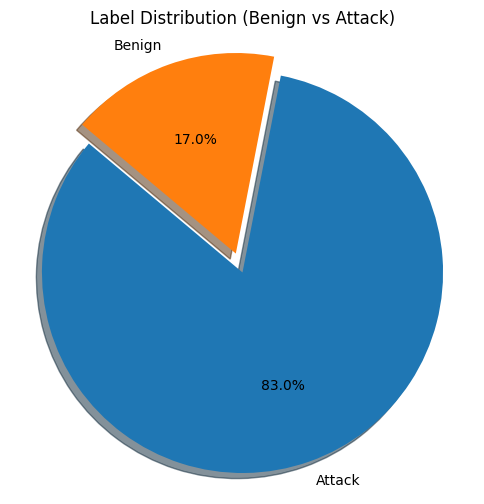

In [12]:
#-------------- Print and plot label distribution ---------------#

label_counts = df[' Label'].value_counts()

print("Class Distribution:\n", label_counts)

plt.figure(figsize=(6, 6))
plt.pie(label_counts, labels=label_counts.index.map({0: 'Benign', 1: 'Attack'}),
        autopct='%1.1f%%', startangle=140, explode=(0.05, 0.05), shadow=True)
plt.title('Label Distribution (Benign vs Attack)')
plt.axis('equal')
plt.show()


## **Data Preprocessing**

In [13]:
#-------------- Display full column names with data types ---------------#

for col in df.columns:
    print(f"{col} : {df[col].dtype}")

 Source Port : int64
 Destination Port : int64
 Protocol : int64
 Timestamp : object
 Flow Duration : int64
 Total Fwd Packets : int64
 Total Backward Packets : int64
Total Length of Fwd Packets : float64
 Total Length of Bwd Packets : float64
 Fwd Packet Length Max : float64
 Fwd Packet Length Min : float64
 Fwd Packet Length Mean : float64
 Fwd Packet Length Std : float64
Bwd Packet Length Max : float64
 Bwd Packet Length Min : float64
 Bwd Packet Length Mean : float64
 Bwd Packet Length Std : float64
Flow Bytes/s : float64
 Flow Packets/s : float64
 Flow IAT Mean : float64
 Flow IAT Std : float64
 Flow IAT Max : float64
 Flow IAT Min : float64
Fwd IAT Total : float64
 Fwd IAT Mean : float64
 Fwd IAT Std : float64
 Fwd IAT Max : float64
 Fwd IAT Min : float64
Bwd IAT Total : float64
 Bwd IAT Mean : float64
 Bwd IAT Std : float64
 Bwd IAT Max : float64
 Bwd IAT Min : float64
Fwd PSH Flags : int64
 Bwd PSH Flags : int64
 Fwd URG Flags : int64
 Bwd URG Flags : int64
 Fwd Header Length :

In [14]:
# -------------------- Drop timestamp & split --------------------

X = df.drop(columns=[' Label', ' Timestamp', 'Estimated_Latency_ms'])  # remove time features completely
y = df[' Label']

# First split: 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# Second split: temp split 50/50 to get 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

# -------------------- MinMax Scaling (No Leakage) --------------------
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit ONLY on training data
X_val_scaled = scaler.transform(X_val)           # transform val
X_test_scaled = scaler.transform(X_test)         # transform test
X_scaled = scaler.transform(X)

# -------------------- Check shapes --------------------
print(f"Training set shape: {X_train_scaled.shape}")
print(f"Validation set shape: {X_val_scaled.shape}")
print(f"Test set shape: {X_test_scaled.shape}")

Training set shape: (439703, 81)
Validation set shape: (94222, 81)
Test set shape: (94223, 81)


## **1. Random Forest**

In [15]:
from sklearn.ensemble import RandomForestClassifier
import time

rf_model = RandomForestClassifier(
    n_estimators=5,           
    max_depth=1,             
    max_features=0.3,      
    min_samples_leaf=20,     
    random_state=42
)
# Measure fit time
start_time = time.time()
rf_model.fit(X_train_scaled, y_train)
fit_time_rf = time.time() - start_time

# Print fit time in seconds
print(f"Random Forest fit time: {fit_time_rf*1000:.4f} ms")


Random Forest fit time: 1014.0412 ms


In [16]:


# ----- Calculate accuracy, precision, recall, F1-score ----- #
rf_y_pred = rf_model.predict(X_test_scaled)
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_precision = precision_score(y_test, rf_y_pred)
rf_recall = recall_score(y_test, rf_y_pred)
rf_f1 = f1_score(y_test, rf_y_pred)

# ----- Measure inference time per sample (in milliseconds) ----- #
start_time = time.time()
_ = rf_model.predict(X_test_scaled)
total_inf_time = time.time() - start_time

# Convert total inference time to per-sample time in milliseconds
model_inf_time_rf = (total_inf_time / len(X_test_scaled)) * 1000

# ----- Print  inference time ----- #

print(f"Random Forest Inference time per sample: {model_inf_time_rf:.6f} ms")


Random Forest Inference time per sample: 0.000312 ms


In [17]:
# ----- Calculate accuracy, precision, recall, F1-score for Random Forest (Train) -----#
rf_y_pred_train = rf_model.predict(X_train_scaled)
rf_accuracy_train = accuracy_score(y_train, rf_y_pred_train)
rf_precision_train = precision_score(y_train, rf_y_pred_train)
rf_recall_train = recall_score(y_train, rf_y_pred_train)
rf_f1_train = f1_score(y_train, rf_y_pred_train)


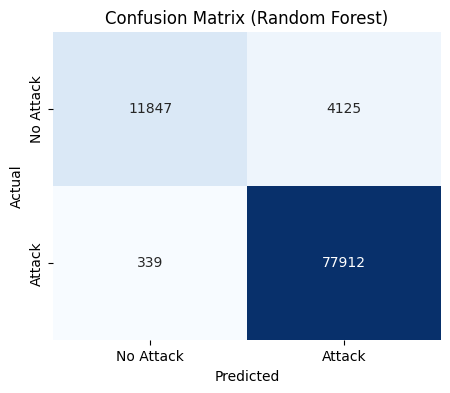

Accuracy (Random Forest): 95.26%
Precision (Random Forest): 94.97%
Recall (Random Forest): 99.57%
F1 Score (Random Forest): 97.22%


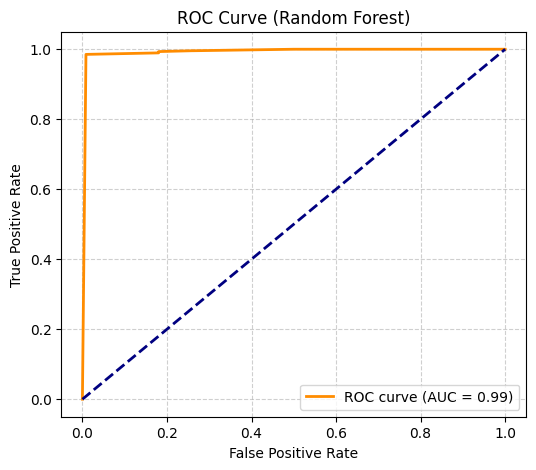

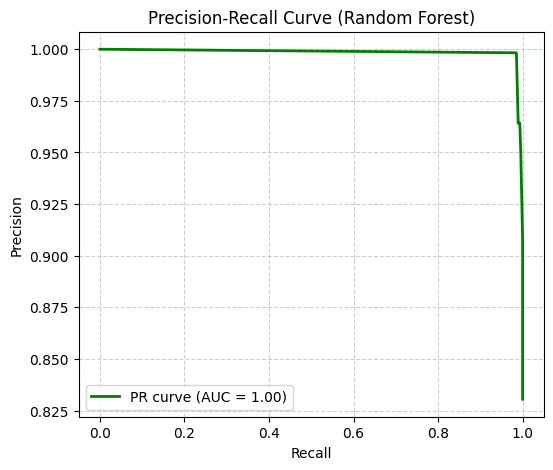

In [18]:
# ----- Confusion Matrix ----- #
conf_matrix = confusion_matrix(y_test, rf_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title('Confusion Matrix (Random Forest)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ----- Print metrics ----- #
print(f'Accuracy (Random Forest): {rf_accuracy * 100:.2f}%')
print(f'Precision (Random Forest): {rf_precision * 100:.2f}%')
print(f'Recall (Random Forest): {rf_recall * 100:.2f}%')
print(f'F1 Score (Random Forest): {rf_f1 * 100:.2f}%')

# ----- ROC Curve and AUC ----- #
rf_y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, rf_y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Random Forest)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ----- Precision-Recall Curve and AUC ----- #
precision, recall, _ = precision_recall_curve(y_test, rf_y_prob)
pr_auc = average_precision_score(y_test, rf_y_prob)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Random Forest)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [19]:
# ----- Adjust latency estimates to include model inference time ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_rf  # Adjust this value based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_rf"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_rf = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_rf"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_rf"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_rf.to_csv("latency_summary_with_model_rf.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_rf)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.000312
1       1  4.654047e+06     96.000312


## **2. SVM**

In [ ]:
# ----- Train an SVM model ----- #


svm_model = SVC(
    kernel='linear',
    probability=True,
    random_state=42
)

# Measure fit time
start_time = time.time()
svm_model.fit(X_train_scaled, y_train)
fit_time_svm = (time.time() - start_time) * 1000  

print(f"SVM fit time: {fit_time_svm:.2f} ms ")


SVM fit time: 5159.09 ms (trained on full dataset)


In [21]:
# ----- Calculate accuracy, precision, recall, F1-score for SVM -----#
svm_y_pred = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, svm_y_pred)
svm_precision = precision_score(y_test, svm_y_pred)
svm_recall = recall_score(y_test, svm_y_pred)
svm_f1 = f1_score(y_test, svm_y_pred)

# ----- Measure inference time per sample (in ms) -----#
start_time = time.time()
_ = svm_model.predict(X_test_scaled)
total_inf_time = time.time() - start_time
model_inf_time_svm = (total_inf_time / len(X_test_scaled)) * 1000

print(f"SVM inference time per sample: {model_inf_time_svm:.6f} ms")


SVM inference time per sample: 0.014394 ms


In [22]:
# ----- Calculate accuracy, precision, recall, F1-score for SVM (Train) -----#
svm_y_pred_train = svm_model.predict(X_train_scaled)
svm_accuracy_train = accuracy_score(y_train, svm_y_pred_train)
svm_precision_train = precision_score(y_train, svm_y_pred_train)
svm_recall_train = recall_score(y_train, svm_y_pred_train)
svm_f1_train = f1_score(y_train, svm_y_pred_train)

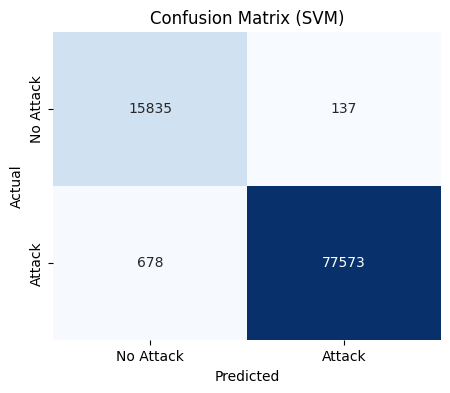

Accuracy (SVM): 99.14%
Precision (SVM): 99.82%
Recall (SVM): 99.13%
F1 Score (SVM): 99.48%


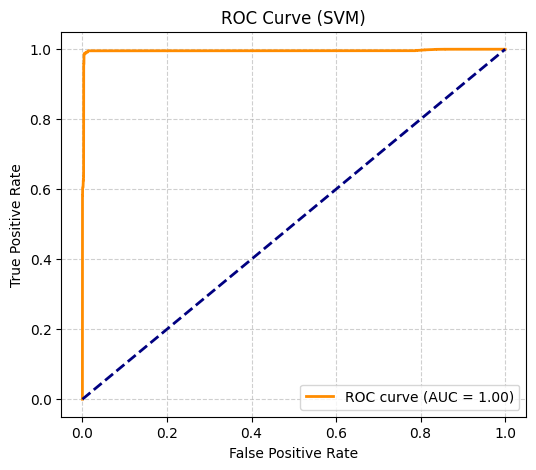

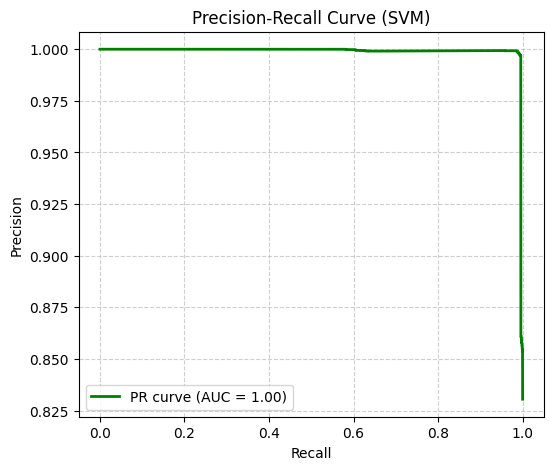

In [23]:
# ----- Confusion Matrix ----- #
conf_matrix = confusion_matrix(y_test, svm_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title('Confusion Matrix (SVM)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ----- Print metrics ----- #
print(f'Accuracy (SVM): {svm_accuracy * 100:.2f}%')
print(f'Precision (SVM): {svm_precision * 100:.2f}%')
print(f'Recall (SVM): {svm_recall * 100:.2f}%')
print(f'F1 Score (SVM): {svm_f1 * 100:.2f}%')

# ----- ROC Curve and AUC ----- #
svm_y_prob = svm_model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, svm_y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (SVM)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ----- Precision-Recall Curve and AUC ----- #
precision, recall, _ = precision_recall_curve(y_test, svm_y_prob)
pr_auc = average_precision_score(y_test, svm_y_prob)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (SVM)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [24]:
# ----- Adjust latency estimates to include model inference time ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_svm  # Adjust this value based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_svm"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_svm = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_svm"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_svm"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_svm.to_csv("latency_summary_with_model_svm.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_svm)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.014394
1       1  4.654047e+06     96.014394


## **3. Decision Tree**

In [25]:

dt_model = DecisionTreeClassifier(
    max_depth=2,
    min_samples_leaf=30,
    splitter='random',
    random_state=42
)

# Measure fit time (in milliseconds)
start_time = time.time()
dt_model.fit(X_train_scaled, y_train)
fit_time_dt = (time.time() - start_time) * 1000  # convert seconds → ms

print(f"Decision Tree fit time: {fit_time_dt:.2f} ms")


Decision Tree fit time: 384.84 ms


In [26]:
# ----- Calculate accuracy, precision, recall, F1-score for Decision Tree -----#
dt_y_pred = dt_model.predict(X_test_scaled)
dt_accuracy = accuracy_score(y_test, dt_y_pred)
dt_precision = precision_score(y_test, dt_y_pred)
dt_recall = recall_score(y_test, dt_y_pred)
dt_f1 = f1_score(y_test, dt_y_pred)

# ----- Measure inference time per sample (in ms) -----#
start_time = time.time()
_ = dt_model.predict(X_test_scaled)
total_inf_time = time.time() - start_time
model_inf_time_dt = (total_inf_time / len(X_test_scaled)) * 1000

print(f"Decision Tree inference time per sample: {model_inf_time_dt:.6f} ms")


Decision Tree inference time per sample: 0.000141 ms


In [27]:
# ----- Calculate accuracy, precision, recall, F1-score for Decision Tree (Train) -----#
dt_y_pred_train = dt_model.predict(X_train_scaled)
dt_accuracy_train = accuracy_score(y_train, dt_y_pred_train)
dt_precision_train = precision_score(y_train, dt_y_pred_train)
dt_recall_train = recall_score(y_train, dt_y_pred_train)
dt_f1_train = f1_score(y_train, dt_y_pred_train)


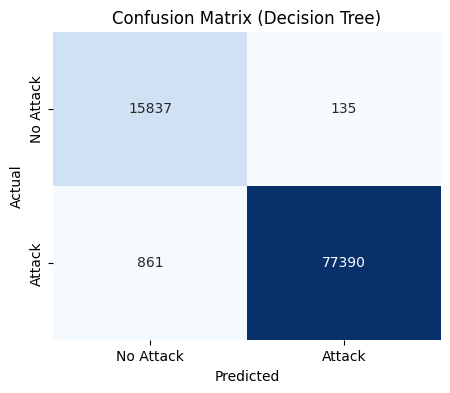

Accuracy (Decision Tree): 98.94%
Precision (Decision Tree): 99.83%
Recall (Decision Tree): 98.90%
F1 Score (Decision Tree): 99.36%


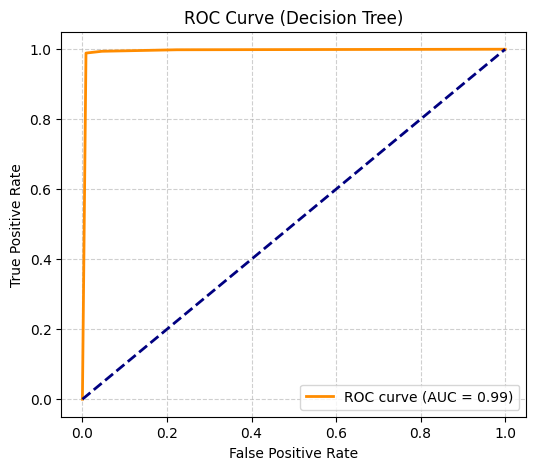

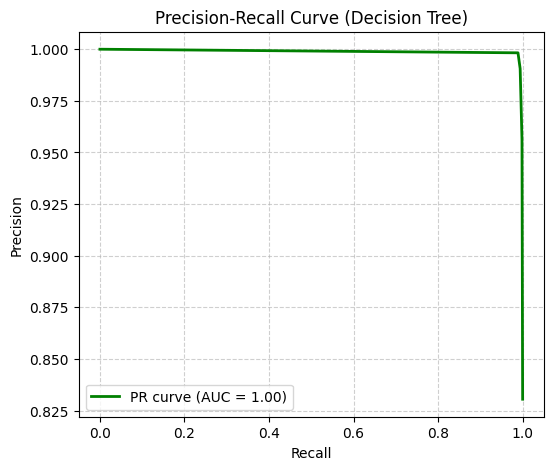

In [28]:
# ----- Confusion Matrix for Decision Tree ----- #
conf_matrix = confusion_matrix(y_test, dt_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title('Confusion Matrix (Decision Tree)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ----- Print metrics ----- #
print(f'Accuracy (Decision Tree): {dt_accuracy * 100:.2f}%')
print(f'Precision (Decision Tree): {dt_precision * 100:.2f}%')
print(f'Recall (Decision Tree): {dt_recall * 100:.2f}%')
print(f'F1 Score (Decision Tree): {dt_f1 * 100:.2f}%')

# ----- ROC Curve and AUC ----- #
dt_y_prob = dt_model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, dt_y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Decision Tree)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ----- Precision-Recall Curve and AUC ----- #
precision, recall, _ = precision_recall_curve(y_test, dt_y_prob)
pr_auc = average_precision_score(y_test, dt_y_prob)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Decision Tree)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [29]:
# ----- Adjust latency estimates to include model inference time (Decision Tree) ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_dt  # Adjust this value based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_dt"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_dt = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_dt"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_dt"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_dt.to_csv("latency_summary_with_model_dt.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_dt)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.000141
1       1  4.654047e+06     96.000141


## **4. Gradient boosting Classifier**

In [30]:
gboost_model = GradientBoostingClassifier(
    n_estimators=10,  
    max_depth=1,
    random_state=42
)

# Measure fit time (in milliseconds)
start_time = time.time()
gboost_model.fit(X_train_scaled, y_train)
fit_time_gb = (time.time() - start_time) * 1000  # convert seconds → ms

print(f"Gradient Boosting fit time: {fit_time_gb:.2f} ms")


Gradient Boosting fit time: 8014.47 ms


In [31]:
# ----- Calculate accuracy, precision, recall, F1-score for Gradient Boosting -----#
gboost_y_pred = gboost_model.predict(X_test_scaled)
gboost_accuracy = accuracy_score(y_test, gboost_y_pred)
gboost_precision = precision_score(y_test, gboost_y_pred)
gboost_recall = recall_score(y_test, gboost_y_pred)
gboost_f1 = f1_score(y_test, gboost_y_pred)

# ----- Measure inference time per sample (in ms) -----#
start_time = time.time()
_ = gboost_model.predict(X_test_scaled)
total_inf_time = time.time() - start_time
model_inf_time_gb = (total_inf_time / len(X_test_scaled)) * 1000

print(f"Gradient Boosting inference time per sample: {model_inf_time_gb:.6f} ms")


Gradient Boosting inference time per sample: 0.000364 ms


In [32]:
# ----- Calculate accuracy, precision, recall, F1-score for Gradient Boosting (Train) -----#
gboost_y_pred_train = gboost_model.predict(X_train_scaled)
gboost_accuracy_train = accuracy_score(y_train, gboost_y_pred_train)
gboost_precision_train = precision_score(y_train, gboost_y_pred_train)
gboost_recall_train = recall_score(y_train, gboost_y_pred_train)
gboost_f1_train = f1_score(y_train, gboost_y_pred_train)


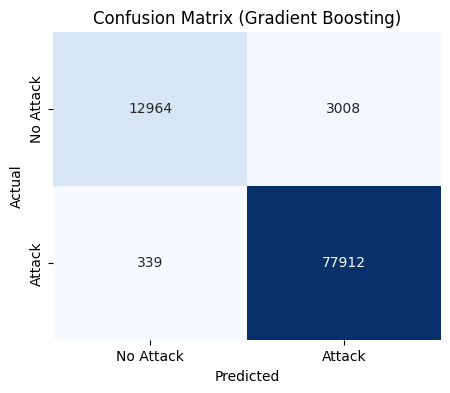

Accuracy (Gradient Boosting): 96.45%
Precision (Gradient Boosting): 96.28%
Recall (Gradient Boosting): 99.57%
F1 Score (Gradient Boosting): 97.90%


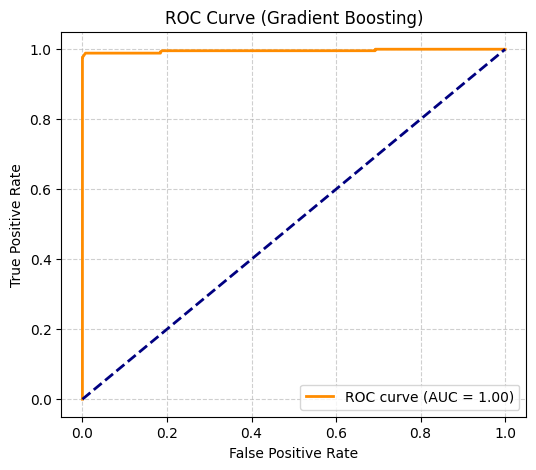

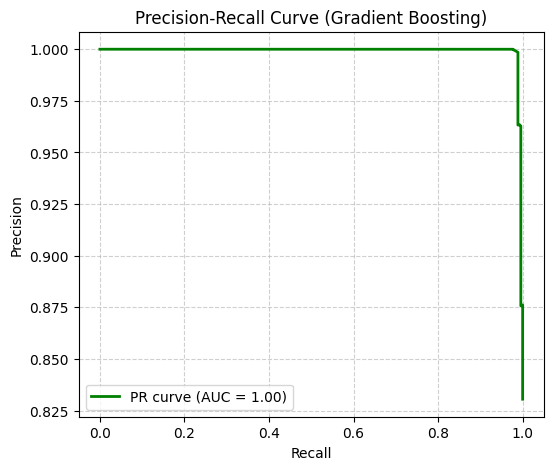

In [33]:
# ----- Confusion Matrix for Gradient Boosting ----- #
conf_matrix = confusion_matrix(y_test, gboost_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title('Confusion Matrix (Gradient Boosting)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ----- Print metrics ----- #
print(f'Accuracy (Gradient Boosting): {gboost_accuracy * 100:.2f}%')
print(f'Precision (Gradient Boosting): {gboost_precision * 100:.2f}%')
print(f'Recall (Gradient Boosting): {gboost_recall * 100:.2f}%')
print(f'F1 Score (Gradient Boosting): {gboost_f1 * 100:.2f}%')

# ----- ROC Curve and AUC ----- #
gboost_y_prob = gboost_model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, gboost_y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Gradient Boosting)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ----- Precision-Recall Curve and AUC ----- #
precision, recall, _ = precision_recall_curve(y_test, gboost_y_prob)
pr_auc = average_precision_score(y_test, gboost_y_prob)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Gradient Boosting)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [34]:
# ----- Adjust latency estimates to include model inference time (Gradient Boosting) ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_gb  # Based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_gb"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_gb = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_gb"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_gb"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_gb.to_csv("latency_summary_with_model_gb.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_gb)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.000364
1       1  4.654047e+06     96.000364


## **5. Ada Boost Classifier**

In [35]:
# ----- Train an AdaBoost classifier model ----- #
adaboost_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, min_samples_leaf=20),
    n_estimators=10,
    learning_rate=0.01,
    random_state=42
)

# Measure fit time (in milliseconds)
start_time = time.time()
adaboost_model.fit(X_train_scaled, y_train)
fit_time_ab = (time.time() - start_time) * 1000  # convert seconds → ms

print(f"AdaBoost fit time: {fit_time_ab:.2f} ms")


AdaBoost fit time: 10736.40 ms


In [36]:
# ----- Calculate accuracy, precision, recall, F1-score for AdaBoost Classifier -----#
adaboost_y_pred = adaboost_model.predict(X_test_scaled)
adaboost_accuracy = accuracy_score(y_test, adaboost_y_pred)
adaboost_precision = precision_score(y_test, adaboost_y_pred)
adaboost_recall = recall_score(y_test, adaboost_y_pred)
adaboost_f1 = f1_score(y_test, adaboost_y_pred)

# ----- Measure inference time per sample (in ms) -----#
start_time = time.time()
_ = adaboost_model.predict(X_test_scaled)
total_inf_time = time.time() - start_time
model_inf_time_ab = (total_inf_time / len(X_test_scaled)) * 1000

print(f"AdaBoost inference time per sample: {model_inf_time_ab:.6f} ms")


AdaBoost inference time per sample: 0.001956 ms


In [37]:
# ----- Calculate accuracy, precision, recall, F1-score for AdaBoost Classifier (Train) -----#
adaboost_y_pred_train = adaboost_model.predict(X_train_scaled)
adaboost_accuracy_train = accuracy_score(y_train, adaboost_y_pred_train)
adaboost_precision_train = precision_score(y_train, adaboost_y_pred_train)
adaboost_recall_train = recall_score(y_train, adaboost_y_pred_train)
adaboost_f1_train = f1_score(y_train, adaboost_y_pred_train)

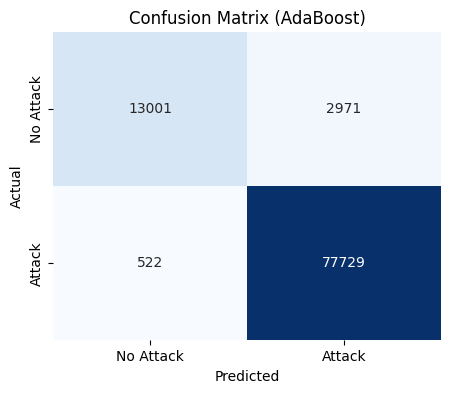

Accuracy (AdaBoost): 96.29%
Precision (AdaBoost): 96.32%
Recall (AdaBoost): 99.33%
F1 Score (AdaBoost): 97.80%


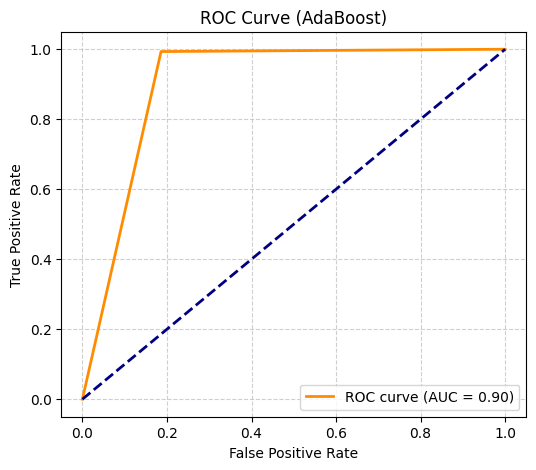

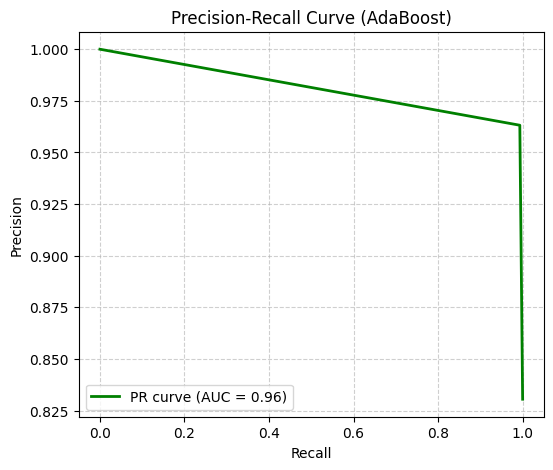

In [38]:
# ----- Confusion Matrix for AdaBoost ----- #
conf_matrix = confusion_matrix(y_test, adaboost_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title('Confusion Matrix (AdaBoost)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ----- Print metrics ----- #
print(f'Accuracy (AdaBoost): {adaboost_accuracy * 100:.2f}%')
print(f'Precision (AdaBoost): {adaboost_precision * 100:.2f}%')
print(f'Recall (AdaBoost): {adaboost_recall * 100:.2f}%')
print(f'F1 Score (AdaBoost): {adaboost_f1 * 100:.2f}%')

# ----- ROC Curve and AUC ----- #
adaboost_y_prob = adaboost_model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, adaboost_y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (AdaBoost)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ----- Precision-Recall Curve and AUC ----- #
precision, recall, _ = precision_recall_curve(y_test, adaboost_y_prob)
pr_auc = average_precision_score(y_test, adaboost_y_prob)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (AdaBoost)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [39]:
# ----- Adjust latency estimates to include model inference time (AdaBoost) ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_ab  # Based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_ab"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_ab = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_ab"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_ab"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_ab.to_csv("latency_summary_with_model_ab.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_ab)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.001956
1       1  4.654047e+06     96.001956


## **6. K-means(Unsupervised)**

In [40]:
!pip install --upgrade --force-reinstall threadpoolctl

  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.6.0
    Uninstalling threadpoolctl-3.6.0:
      Successfully uninstalled threadpoolctl-3.6.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.
imbalanced-learn 0.13.0 requires scikit-learn<2,>=1.3.2, but you have scikit-learn 1.2.2 which is incompatible.
umap-learn 0.5.9.post2 requires scikit-learn>=1.6, but you have scikit-learn 1.2.2 which is incompatible.
mlxtend 0.23.4 requires scikit-learn>=1.3.1, but you have scikit-learn 1.2.2 which is incompatible.


In [41]:

# ----- Train a K-Means model -----#
kmeans_model = KMeans(n_clusters=2, random_state=42, n_init=100)  # 2 clusters

# Measure fit time (in milliseconds)
start_time = time.time()
kmeans_labels = kmeans_model.fit_predict(X_train_scaled)
fit_time_kmeans = (time.time() - start_time) * 1000  # convert seconds → ms

print(f"K-Means fit time: {fit_time_kmeans:.2f} ms")


K-Means fit time: 29719.84 ms


In [42]:
# ----- Match clusters to actual labels for K-Means -----#
def map_clusters_to_labels(cluster_labels, true_labels):
    """ Maps K-Means/DBSCAN clusters to actual labels using majority voting. """
    label_map = {}
    for cluster in np.unique(cluster_labels):
        mask = (cluster_labels == cluster)
        majority_label = mode(true_labels[mask], keepdims=True).mode[0]  # Corrected access
        label_map[cluster] = majority_label
    return np.array([label_map[label] for label in cluster_labels])

kmeans_mapped_labels = map_clusters_to_labels(kmeans_labels, y_train)

In [43]:
# ----- Calculate metrics for K-Means -----#
kmeans_accuracy = accuracy_score(y_train, kmeans_mapped_labels)
kmeans_precision = precision_score(y_train, kmeans_mapped_labels)
kmeans_recall = recall_score(y_train, kmeans_mapped_labels)
kmeans_f1 = f1_score(y_train, kmeans_mapped_labels)


In [44]:
# ----- Measure K-Means inference time per sample (in ms) -----#
start_time = time.time()
_ = kmeans_model.predict(X_test_scaled)  # assign clusters to test data
total_inf_time = time.time() - start_time
model_inf_time_kmeans = (total_inf_time / len(X_test_scaled)) * 1000  # per-sample time in ms

print(f"K-Means inference time per sample: {model_inf_time_kmeans:.6f} ms")

K-Means inference time per sample: 0.000421 ms


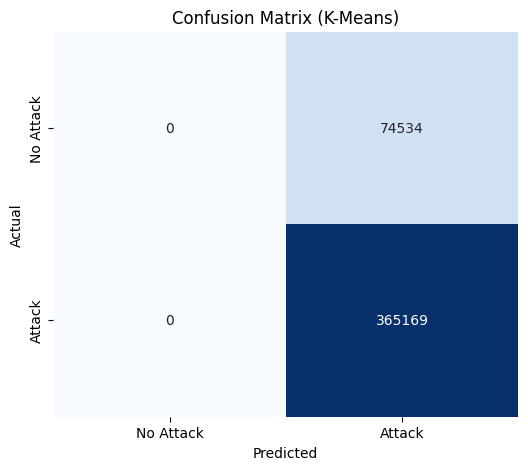

Accuracy (K-Means): 0.8305
Precision (K-Means): 0.8305
Recall (K-Means): 1.0000
F1 Score (K-Means): 0.9074


In [45]:
# ----- Plot Confusion Matrix for K-Means -----#
kmeans_conf_matrix = confusion_matrix(y_train, kmeans_mapped_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(kmeans_conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title('Confusion Matrix (K-Means)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ----- Print metrics for K-Means -----#
print(f'Accuracy (K-Means): {kmeans_accuracy:.4f}')
print(f'Precision (K-Means): {kmeans_precision:.4f}')
print(f'Recall (K-Means): {kmeans_recall:.4f}')
print(f'F1 Score (K-Means): {kmeans_f1:.4f}')

In [46]:
# ----- Adjust latency estimates to include model inference time (K-Means) ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_kmeans  # Based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_kmeans"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_kmeans = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_kmeans"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_kmeans"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_kmeans.to_csv("latency_summary_with_model_kmeans.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_kmeans)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.000421
1       1  4.654047e+06     96.000421


## **7. DBScan(Unsupervised)**

In [47]:
import time
from sklearn.cluster import DBSCAN
from sklearn.utils import shuffle

# ----- Take a random sample of the data to reduce size -----#
# ----- Shuffle and sample 10% of the data to avoid memory crash -----#
X_train_sampled, y_train_sampled = shuffle(X_train_scaled, y_train, random_state=42)
X_train_sampled = X_train_sampled[:int(0.1 * len(X_train_scaled))]
y_train_sampled = y_train_sampled[:int(0.1 * len(y_train))]

# ----- Train a DBSCAN model on the sampled data -----#
dbscan_model = DBSCAN(eps=0.5, min_samples=5)

# Measure fit time (in milliseconds)
start_time = time.time()
dbscan_labels = dbscan_model.fit_predict(X_train_sampled)
fit_time_dbscan = (time.time() - start_time) * 1000  # convert seconds → ms

print(f"DBSCAN fit time: {fit_time_dbscan:.2f} ms")


DBSCAN fit time: 8560.94 ms


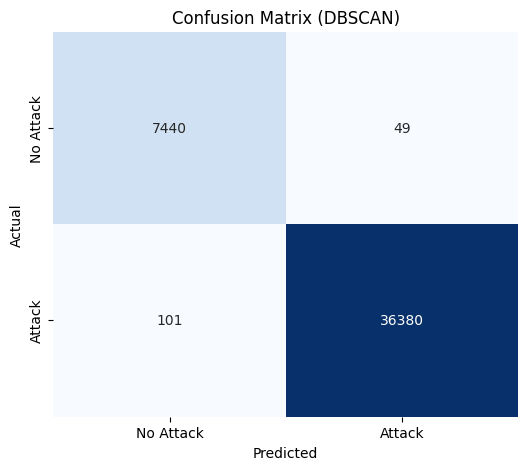

Accuracy (DBSCAN): 0.9966
Precision (DBSCAN): 0.9987
Recall (DBSCAN): 0.9972
F1 Score (DBSCAN): 0.9979


In [48]:
# ----- Check if DBSCAN produced valid clusters -----#
if len(set(dbscan_labels)) > 1:
    dbscan_mapped_labels = map_clusters_to_labels(dbscan_labels, y_train_sampled)

    # ----- Calculate metrics for DBSCAN -----#
    dbscan_accuracy = accuracy_score(y_train_sampled, dbscan_mapped_labels)
    dbscan_precision = precision_score(y_train_sampled, dbscan_mapped_labels)
    dbscan_recall = recall_score(y_train_sampled, dbscan_mapped_labels)
    dbscan_f1 = f1_score(y_train_sampled, dbscan_mapped_labels)
    dbscan_conf_matrix = confusion_matrix(y_train_sampled, dbscan_mapped_labels)

    # ----- Plot Confusion Matrix for DBSCAN -----#
    plt.figure(figsize=(6, 5))
    sns.heatmap(dbscan_conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
    plt.title('Confusion Matrix (DBSCAN)')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # ----- Print metrics for DBSCAN -----#
    print(f'Accuracy (DBSCAN): {dbscan_accuracy:.4f}')
    print(f'Precision (DBSCAN): {dbscan_precision:.4f}')
    print(f'Recall (DBSCAN): {dbscan_recall:.4f}')
    print(f'F1 Score (DBSCAN): {dbscan_f1:.4f}')



else:
    print("DBSCAN detected only one cluster; silhouette score is undefined.")

## **8. MLP(Deep Learning)**

In [49]:
# ----- Define MLP Model -----#
mlp_model = tf.keras.Sequential([
    tf.keras.layers.Dense(128, activation='relu', input_dim=X_train.shape[1]),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1761309881.850277      37 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


In [50]:
# ----- Compile MLP Model -----#
mlp_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [51]:
# ----- Train the MLP Model -----#
start_time = time.time()
mlp_history = mlp_model.fit(
    X_train_scaled, y_train,
    epochs=3,
    batch_size=32,
    validation_data=(X_val_scaled, y_val),
    verbose=1
)
fit_time_mlp = (time.time() - start_time) * 1000  # convert seconds → ms

print(f"MLP fit time: {fit_time_mlp:.2f} ms")

Epoch 1/3


I0000 00:00:1761309884.658417     107 service.cc:148] XLA service 0x7bec5c006ac0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1761309884.658924     107 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1761309884.885086     107 cuda_dnn.cc:529] Loaded cuDNN version 90300


   74/13741 ━━━━━━━━━━━━━━━━━━━━ 28s 2ms/step - accuracy: 0.7879 - loss: 0.4235 

I0000 00:00:1761309885.410125     107 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


13741/13741 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.9934 - loss: 0.0185 - val_accuracy: 0.9995 - val_loss: 0.0020
Epoch 2/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - accuracy: 0.9995 - loss: 0.0020 - val_accuracy: 0.9996 - val_loss: 0.0018
Epoch 3/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 34s 2ms/step - accuracy: 0.9996 - loss: 0.0014 - val_accuracy: 0.9995 - val_loss: 0.0014
MLP fit time: 105892.20 ms


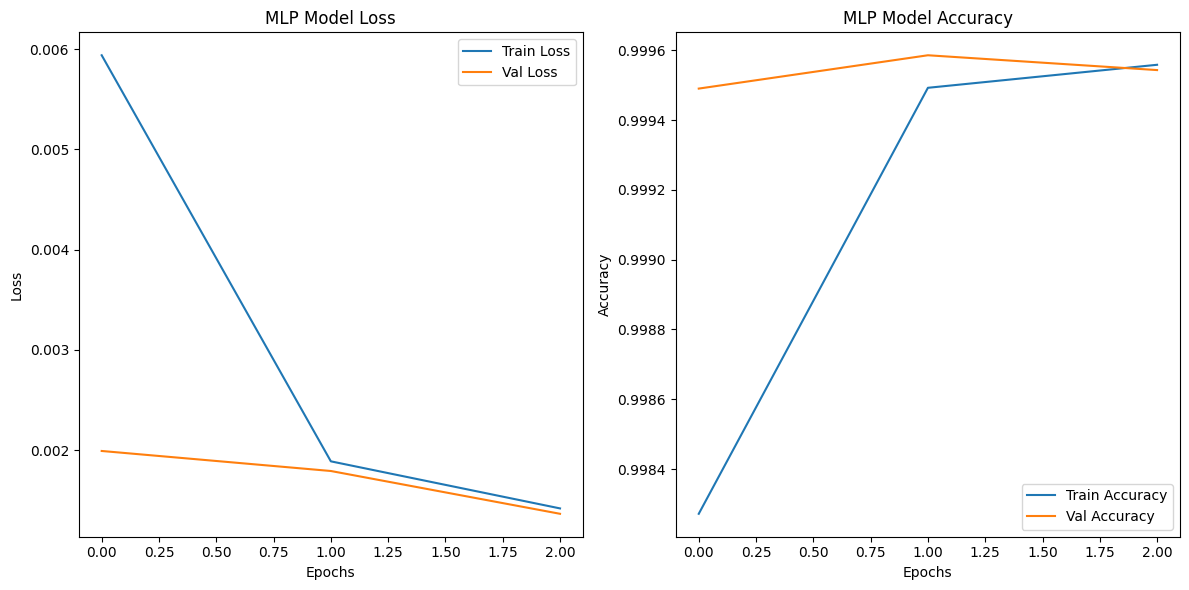

In [52]:
# ----- Plotting MLP Loss and Accuracy -----#
plt.figure(figsize=(12, 6))
#Loss
plt.subplot(1, 2, 1)
plt.plot(mlp_history.history['loss'], label='Train Loss')
plt.plot(mlp_history.history['val_loss'], label='Val Loss')
plt.title('MLP Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

#Accuracy
plt.subplot(1, 2, 2)
plt.plot(mlp_history.history['accuracy'], label='Train Accuracy')
plt.plot(mlp_history.history['val_accuracy'], label='Val Accuracy')
plt.title('MLP Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


In [53]:
# ----- Get Predictions and Metrics for MLP -----#
mlp_y_pred = (mlp_model.predict(X_test_scaled) > 0.5).astype("int32")
mlp_accuracy = accuracy_score(y_test, mlp_y_pred)
mlp_precision = precision_score(y_test, mlp_y_pred)
mlp_recall = recall_score(y_test, mlp_y_pred)
mlp_f1 = f1_score(y_test, mlp_y_pred)

# ----- Measure inference time per sample (in ms) -----#
import time
start_time = time.time()
_ = mlp_model.predict(X_test_scaled)
total_inf_time = time.time() - start_time
model_inf_time_mlp = (total_inf_time / len(X_test_scaled)) * 1000

print(f"MLP inference time per sample: {model_inf_time_mlp:.6f} ms")


2945/2945 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
2945/2945 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
MLP inference time per sample: 0.049622 ms


In [54]:
# ----- Get Predictions and Metrics for MLP (Train) -----
mlp_y_pred_train = (mlp_model.predict(X_train_scaled) > 0.5).astype("int32")
mlp_accuracy_train = accuracy_score(y_train, mlp_y_pred_train)
mlp_precision_train = precision_score(y_train, mlp_y_pred_train)
mlp_recall_train = recall_score(y_train, mlp_y_pred_train)
mlp_f1_train = f1_score(y_train, mlp_y_pred_train)


13741/13741 ━━━━━━━━━━━━━━━━━━━━ 16s 1ms/step


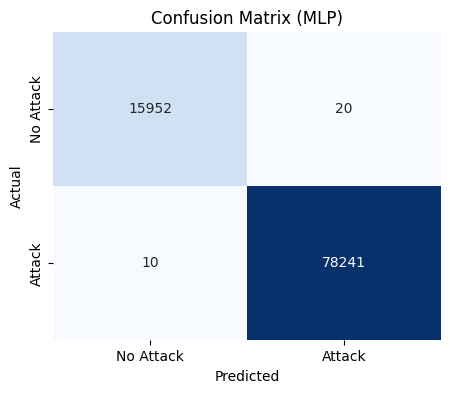

Accuracy (MLP): 99.9682%
Precision (MLP): 99.9744%
Recall (MLP): 99.9872%
F1 Score (MLP): 99.9808%
2945/2945 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step


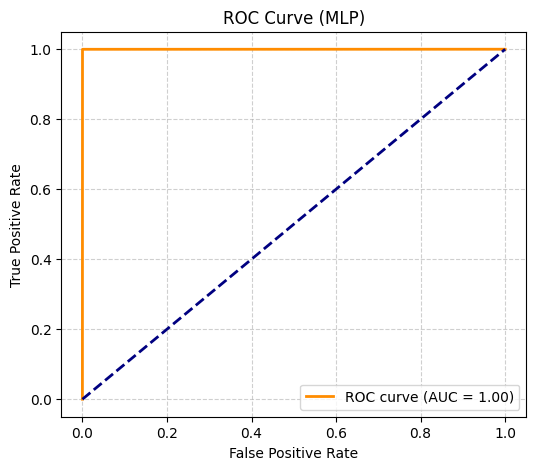

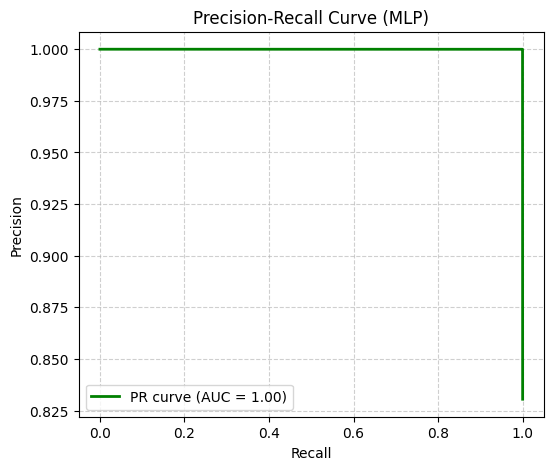

In [55]:
# ----- Confusion Matrix for MLP ----- #
mlp_cm = confusion_matrix(y_test, mlp_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(mlp_cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title('Confusion Matrix (MLP)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ----- Print metrics ----- #
print(f'Accuracy (MLP): {mlp_accuracy * 100:.4f}%')
print(f'Precision (MLP): {mlp_precision * 100:.4f}%')
print(f'Recall (MLP): {mlp_recall * 100:.4f}%')
print(f'F1 Score (MLP): {mlp_f1 * 100:.4f}%')

# ----- ROC Curve and AUC ----- #
mlp_y_prob = mlp_model.predict(X_test_scaled).ravel()  # probabilities from sigmoid

fpr, tpr, _ = roc_curve(y_test, mlp_y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (MLP)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ----- Precision-Recall Curve and AUC ----- #
precision, recall, _ = precision_recall_curve(y_test, mlp_y_prob)
pr_auc = average_precision_score(y_test, mlp_y_prob)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (MLP)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [56]:
# ----- Adjust latency estimates to include model inference time (MLP) ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_mlp  # Based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_mlp"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_mlp = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_mlp"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_mlp"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_mlp.to_csv("latency_summary_with_model_mlp.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_mlp)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.049622
1       1  4.654047e+06     96.049622


## **9. LSTM(Deep Learning)**

In [57]:
# ----- Reshape the data for LSTM -----#


# Note: LSTM (Long Short-Term Memory) networks are a type of Recurrent Neural Network (RNN) that expect input data to be in a 3D shape:
# (samples, timesteps, features).
# In this case:
# - 'samples' refers to the number of data points (e.g., the number of rows in the dataset).
# - 'timesteps' refers to the number of time steps or sequence length. Since we are working with tabular data,
#   we treat each feature as a time step.
# - 'features' is the number of features per timestep. In this case, each feature is represented as one "column" of data.
# Hence, we reshape the data to (number_of_samples, number_of_features, 1), where 1 indicates that we treat each feature as
# a separate "timing" step in the sequence. This enables the LSTM to process the data appropriately.


X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_val_lstm = X_val_scaled.reshape((X_val_scaled.shape[0], X_val_scaled.shape[1], 1))
X_test_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], X_test_scaled.shape[1], 1))


In [58]:
# ----- Define LSTM Model -----#
lstm_model = tf.keras.Sequential([
    tf.keras.layers.LSTM(128, activation='relu', input_shape=(X_train_lstm.shape[1], 1), return_sequences=True),
    tf.keras.layers.LSTM(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [59]:
# ----- Compile LSTM Model -----#
lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


In [60]:
# ----- Train the LSTM Model -----#
start_time = time.time()
lstm_history = lstm_model.fit(
    X_train_lstm, y_train,
    epochs=3,
    batch_size=32,
    validation_data=(X_val_lstm, y_val),
    verbose=1
)
fit_time_lstm = (time.time() - start_time) * 1000  # convert seconds → ms

print(f"LSTM fit time: {fit_time_lstm:.2f} ms")

Epoch 1/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 248s 18ms/step - accuracy: 0.8582 - loss: 1.2957 - val_accuracy: 0.9848 - val_loss: 0.0693
Epoch 2/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 241s 18ms/step - accuracy: 0.9600 - loss: 2975.9282 - val_accuracy: 0.9887 - val_loss: 0.0498
Epoch 3/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 241s 18ms/step - accuracy: 0.9775 - loss: 0.0908 - val_accuracy: 0.9916 - val_loss: 0.0303
LSTM fit time: 730370.25 ms


In [61]:
# ----- Get Predictions and Metrics for LSTM -----#
lstm_y_pred = (lstm_model.predict(X_test_lstm) > 0.5).astype("int32")
lstm_accuracy = accuracy_score(y_test, lstm_y_pred)
lstm_precision = precision_score(y_test, lstm_y_pred)
lstm_recall = recall_score(y_test, lstm_y_pred)
lstm_f1 = f1_score(y_test, lstm_y_pred)

# ----- Measure inference time per sample (in ms) -----#
import time
start_time = time.time()
_ = lstm_model.predict(X_test_lstm)
total_inf_time = time.time() - start_time
model_inf_time_lstm = (total_inf_time / len(X_test_lstm)) * 1000  # convert seconds → ms

print(f"LSTM inference time per sample: {model_inf_time_lstm:.6f} ms")


2945/2945 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step
2945/2945 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step
LSTM inference time per sample: 0.153250 ms


In [62]:
# ----- Get Predictions and Metrics for LSTM (Train) -----
lstm_y_pred_train = (lstm_model.predict(X_train_lstm) > 0.5).astype("int32")
lstm_accuracy_train = accuracy_score(y_train, lstm_y_pred_train)
lstm_precision_train = precision_score(y_train, lstm_y_pred_train)
lstm_recall_train = recall_score(y_train, lstm_y_pred_train)
lstm_f1_train = f1_score(y_train, lstm_y_pred_train)


13741/13741 ━━━━━━━━━━━━━━━━━━━━ 62s 5ms/step


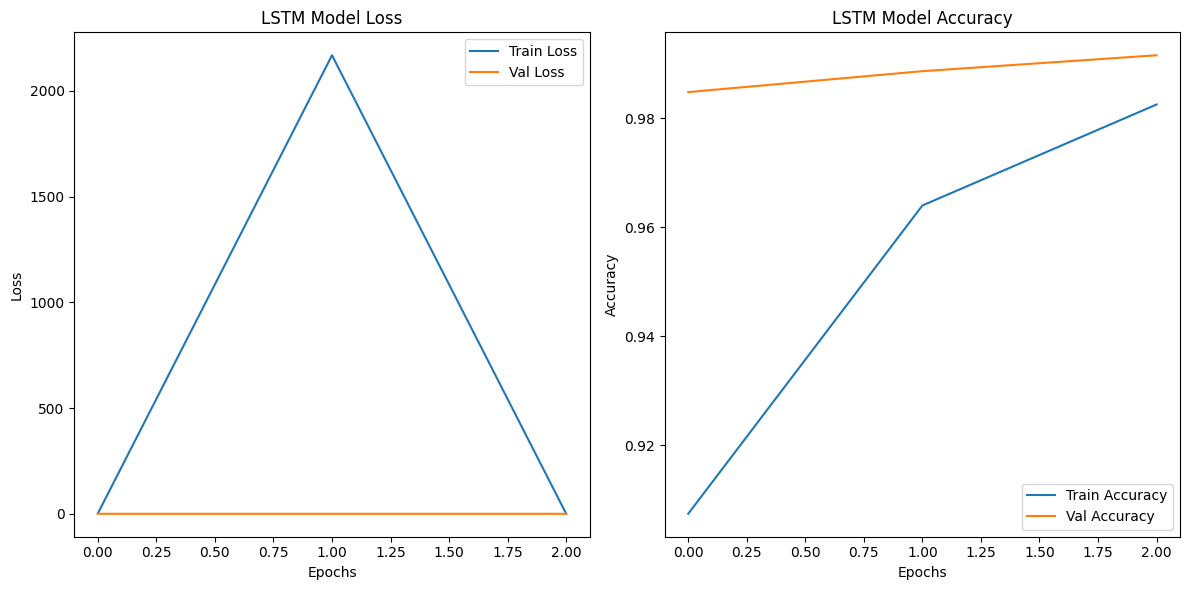

In [63]:
# ----- Plotting LSTM Loss and Accuracy -----#
plt.figure(figsize=(12, 6))
#Loss
plt.subplot(1, 2, 1)
plt.plot(lstm_history.history['loss'], label='Train Loss')
plt.plot(lstm_history.history['val_loss'], label='Val Loss')
plt.title('LSTM Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

#Accuracy
plt.subplot(1, 2, 2)
plt.plot(lstm_history.history['accuracy'], label='Train Accuracy')
plt.plot(lstm_history.history['val_accuracy'], label='Val Accuracy')
plt.title('LSTM Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


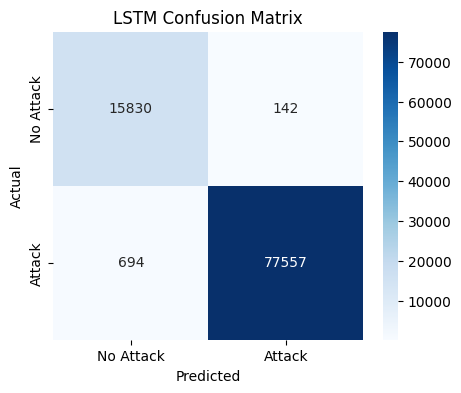

LSTM Model Metrics:
Accuracy: 0.99
Precision: 1.00
Recall: 0.99
F1 Score: 0.99


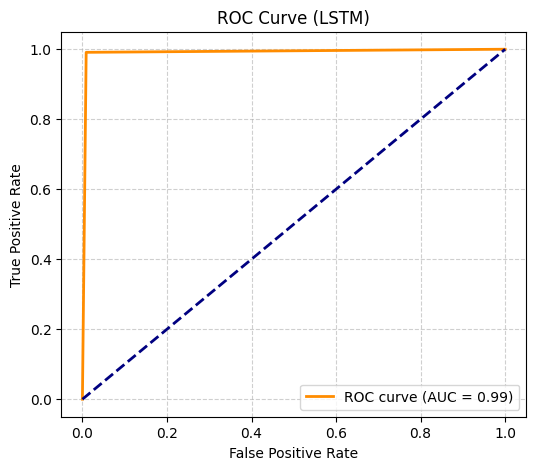

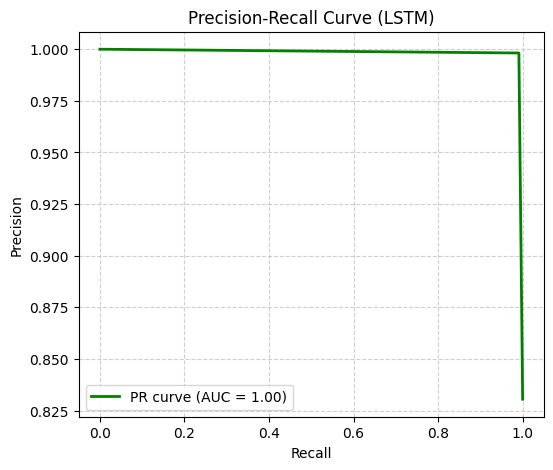

In [64]:
# ----- LSTM Metrics and Confusion Matrix ----- #
lstm_cm = confusion_matrix(y_test, lstm_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(lstm_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ----- Print metrics ----- #
print("LSTM Model Metrics:")
print(f"Accuracy: {lstm_accuracy:.2f}")
print(f"Precision: {lstm_precision:.2f}")
print(f"Recall: {lstm_recall:.2f}")
print(f"F1 Score: {lstm_f1:.2f}")

# ----- ROC Curve and AUC ----- #
# lstm_y_prob = lstm_model.predict(X_test_scaled).ravel()  # probabilities from sigmoid output

fpr, tpr, _ = roc_curve(y_test, lstm_y_pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1],[0,1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (LSTM)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ----- Precision-Recall Curve and AUC ----- #
precision, recall, _ = precision_recall_curve(y_test, lstm_y_pred)
pr_auc = average_precision_score(y_test, lstm_y_pred)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (LSTM)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [65]:
# ----- Adjust latency estimates to include model inference time (LSTM) ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_lstm  # Based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_lstm"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_lstm = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_lstm"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_lstm"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_lstm.to_csv("latency_summary_with_model_lstm.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_lstm)


    Label       mean_ms    median_ms
0       0  1.107659e+07  27924.15325
1       1  4.654047e+06     96.15325


## **10. BiLSTM(Deep Learning)**

In [66]:
# ----- Define BiLSTM Model -----#
bilstm_model = tf.keras.Sequential([
    Bidirectional(tf.keras.layers.LSTM(128, activation='relu', return_sequences=True), input_shape=(X_train_lstm.shape[1], 1)),
    Bidirectional(tf.keras.layers.LSTM(64, activation='relu')),
    tf.keras.layers.Dense(1, activation='sigmoid')  # For binary classification (change activation if needed)
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [67]:
# ----- Compile BiLSTM Model -----#
bilstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [68]:
# ----- Train the BiLSTM Model -----#
start_time = time.time()
bilstm_history = bilstm_model.fit(
    X_train_lstm, y_train,
    epochs=2,
    batch_size=32,
    validation_data=(X_val_lstm, y_val),
    verbose=1
)
fit_time_bilstm = (time.time() - start_time) * 1000  # convert seconds → ms

print(f"BiLSTM fit time: {fit_time_bilstm:.2f} ms")

Epoch 1/2
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 483s 34ms/step - accuracy: 0.8321 - loss: 0.9674 - val_accuracy: 0.8305 - val_loss: 0.3265
Epoch 2/2
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 466s 34ms/step - accuracy: 0.9542 - loss: 43286.5273 - val_accuracy: 0.9828 - val_loss: 0.0952
BiLSTM fit time: 948784.40 ms


In [69]:
# ----- Get Predictions and Metrics for BiLSTM -----#
bilstm_y_pred = (bilstm_model.predict(X_test_lstm) > 0.5).astype("int32")
bilstm_accuracy = accuracy_score(y_test, bilstm_y_pred)
bilstm_precision = precision_score(y_test, bilstm_y_pred)
bilstm_recall = recall_score(y_test, bilstm_y_pred)
bilstm_f1 = f1_score(y_test, bilstm_y_pred)

# ----- Measure inference time per sample (in ms) -----#
import time
start_time = time.time()
_ = bilstm_model.predict(X_test_lstm)
total_inf_time = time.time() - start_time
model_inf_time_bilstm = (total_inf_time / len(X_test_lstm)) * 1000  # convert seconds → ms

print(f"BiLSTM inference time per sample: {model_inf_time_bilstm:.6f} ms")


2945/2945 ━━━━━━━━━━━━━━━━━━━━ 28s 9ms/step
2945/2945 ━━━━━━━━━━━━━━━━━━━━ 26s 9ms/step
BiLSTM inference time per sample: 0.284813 ms


In [70]:
# ----- Get Predictions and Metrics for BiLSTM (Train) -----
bilstm_y_pred_train = (bilstm_model.predict(X_train_lstm) > 0.5).astype("int32")
bilstm_accuracy_train = accuracy_score(y_train, bilstm_y_pred_train)
bilstm_precision_train = precision_score(y_train, bilstm_y_pred_train)
bilstm_recall_train = recall_score(y_train, bilstm_y_pred_train)
bilstm_f1_train = f1_score(y_train, bilstm_y_pred_train)


13741/13741 ━━━━━━━━━━━━━━━━━━━━ 120s 9ms/step


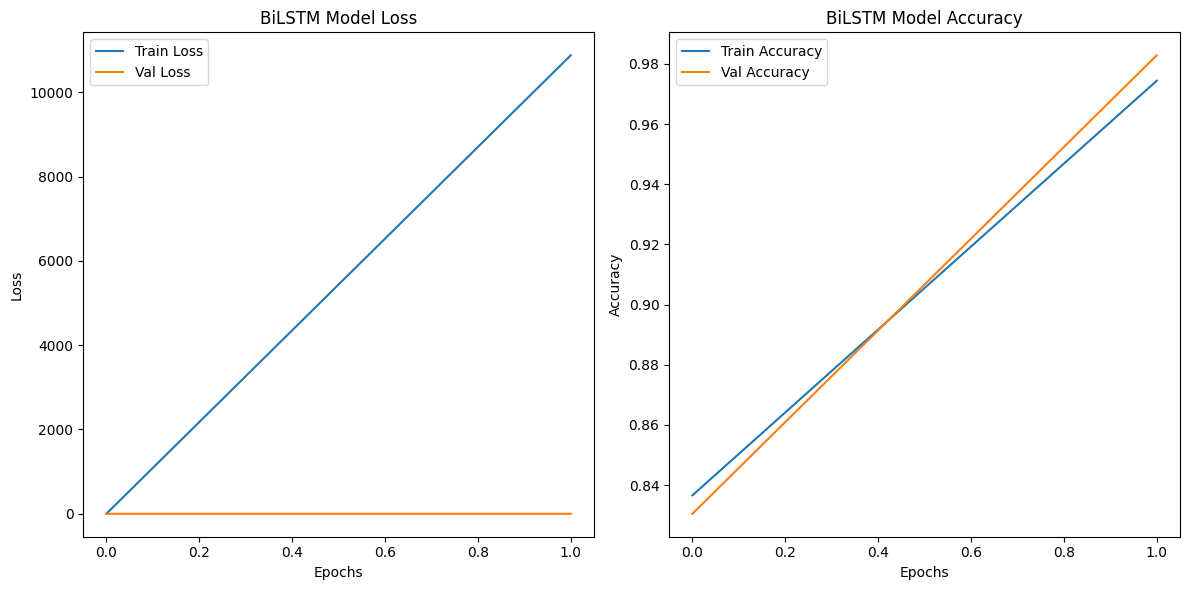

In [71]:
# ----- Plotting BiLSTM Loss and Accuracy -----#
plt.figure(figsize=(12, 6))
# Loss
plt.subplot(1, 2, 1)
plt.plot(bilstm_history.history['loss'], label='Train Loss')
plt.plot(bilstm_history.history['val_loss'], label='Val Loss')
plt.title('BiLSTM Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(bilstm_history.history['accuracy'], label='Train Accuracy')
plt.plot(bilstm_history.history['val_accuracy'], label='Val Accuracy')
plt.title('BiLSTM Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

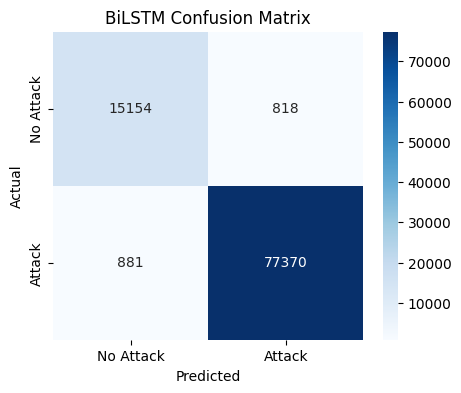

BiLSTM Model Metrics:
Accuracy: 0.98
Precision: 0.99
Recall: 0.99
F1 Score: 0.99


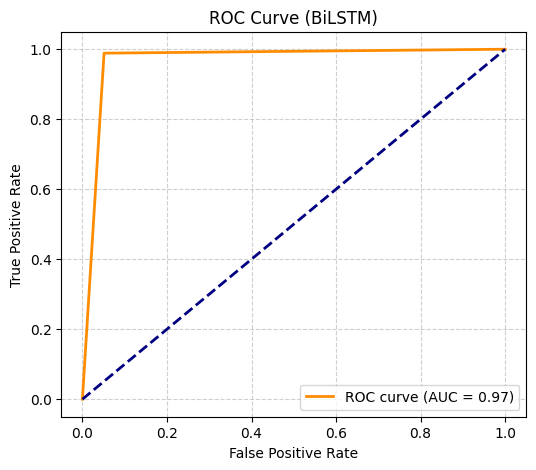

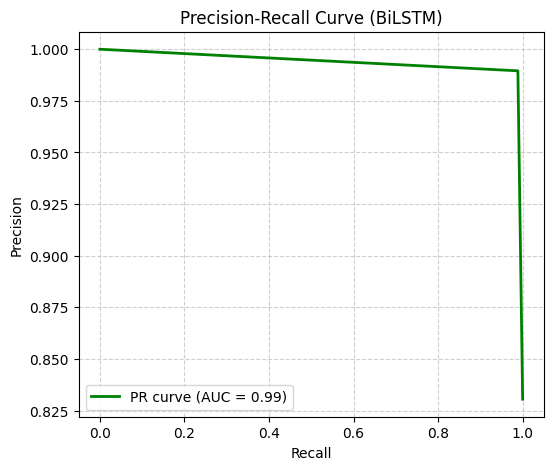

In [72]:
# ----- BiLSTM Metrics and Confusion Matrix ----- #
bilstm_cm = confusion_matrix(y_test, bilstm_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(bilstm_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title("BiLSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ----- Print metrics ----- #
print("BiLSTM Model Metrics:")
print(f"Accuracy: {bilstm_accuracy:.2f}")
print(f"Precision: {bilstm_precision:.2f}")
print(f"Recall: {bilstm_recall:.2f}")
print(f"F1 Score: {bilstm_f1:.2f}")

# ----- ROC Curve and AUC ----- #
# bilstm_y_prob = bilstm_model.predict(X_test_scaled).ravel()  # probabilities from sigmoid

fpr, tpr, _ = roc_curve(y_test, bilstm_y_pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1],[0,1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (BiLSTM)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ----- Precision-Recall Curve and AUC ----- #
precision, recall, _ = precision_recall_curve(y_test, bilstm_y_pred)
pr_auc = average_precision_score(y_test, bilstm_y_pred)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (BiLSTM)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [73]:
# ----- Adjust latency estimates to include model inference time (BiLSTM) ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_bilstm  # Based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_bilstm"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_bilstm = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_bilstm"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_bilstm"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_bilstm.to_csv("latency_summary_with_model_bilstm.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_bilstm)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.284813
1       1  4.654047e+06     96.284813


## **11. CNN-LSTM(Hybrid)**

In [74]:
# ----- Reshape the data for CNN-LSTM -----
# We now use Conv1D which requires the input shape to be (samples, timesteps, features)
# So the data needs to be reshaped into (samples, features, 1), where 1 is the "channel".
X_train_cnn_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_val_cnn_lstm = X_val_scaled.reshape((X_val_scaled.shape[0], X_val_scaled.shape[1], 1))
X_test_cnn_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], X_test_scaled.shape[1], 1))

In [75]:
# ----- Define CNN-LSTM Hybrid Model -----
cnn_lstm_model = tf.keras.Sequential([
    # CNN layers for feature extraction
    tf.keras.layers.Conv1D(32, 3, activation='relu', input_shape=(X_train_cnn_lstm.shape[1], 1)),
    tf.keras.layers.MaxPooling1D(pool_size=2),

    tf.keras.layers.Conv1D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling1D(pool_size=2),

    tf.keras.layers.Conv1D(128, 3, activation='relu'),
    tf.keras.layers.MaxPooling1D(pool_size=2),

    # Calculate the output shape dynamically based on the pooling layers
    # Reshape the output from CNN layers to be compatible with LSTM
    tf.keras.layers.Reshape((-1, 128)),  # -1 will infer the correct timesteps

    # LSTM layers for classification
    tf.keras.layers.LSTM(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [76]:
# ----- Compile CNN-LSTM Model -----
cnn_lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [77]:

# ----- Train the CNN-LSTM Model ----- #
start_time = time.time()
cnn_lstm_history = cnn_lstm_model.fit(
    X_train_cnn_lstm, y_train,
    epochs=3,
    batch_size=32,
    validation_data=(X_val_cnn_lstm, y_val),
    verbose=1
)
fit_time_cnn_lstm = (time.time() - start_time) * 1000  # convert seconds → ms

print(f"CNN-LSTM fit time: {fit_time_cnn_lstm:.2f} ms")

Epoch 1/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 61s 4ms/step - accuracy: 0.9731 - loss: 0.0685 - val_accuracy: 0.9911 - val_loss: 0.0228
Epoch 2/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 51s 4ms/step - accuracy: 0.9924 - loss: 0.0195 - val_accuracy: 0.9933 - val_loss: 0.0159
Epoch 3/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 52s 4ms/step - accuracy: 0.9934 - loss: 0.0164 - val_accuracy: 0.9948 - val_loss: 0.0152
CNN-LSTM fit time: 164062.10 ms


In [78]:
# ----- Get Predictions and Metrics for CNN-LSTM -----
cnn_lstm_y_pred = (cnn_lstm_model.predict(X_test_cnn_lstm) > 0.5).astype("int32")
cnn_lstm_accuracy = accuracy_score(y_test, cnn_lstm_y_pred)
cnn_lstm_precision = precision_score(y_test, cnn_lstm_y_pred)
cnn_lstm_recall = recall_score(y_test, cnn_lstm_y_pred)
cnn_lstm_f1 = f1_score(y_test, cnn_lstm_y_pred)

# ----- Measure inference time per sample (in ms) ----- #
import time
start_time = time.time()
_ = cnn_lstm_model.predict(X_test_cnn_lstm)
total_inf_time = time.time() - start_time
model_inf_time_cnn_lstm = (total_inf_time / len(X_test_cnn_lstm)) * 1000  # convert seconds → ms

print(f"CNN-LSTM inference time per sample: {model_inf_time_cnn_lstm:.6f} ms")


2945/2945 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
2945/2945 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
CNN-LSTM inference time per sample: 0.058835 ms


In [79]:
# ----- Get Predictions and Metrics for CNN-LSTM (Train) -----
cnn_lstm_y_pred_train = (cnn_lstm_model.predict(X_train_cnn_lstm) > 0.5).astype("int32")
cnn_lstm_accuracy_train = accuracy_score(y_train, cnn_lstm_y_pred_train)
cnn_lstm_precision_train = precision_score(y_train, cnn_lstm_y_pred_train)
cnn_lstm_recall_train = recall_score(y_train, cnn_lstm_y_pred_train)
cnn_lstm_f1_train = f1_score(y_train, cnn_lstm_y_pred_train)


13741/13741 ━━━━━━━━━━━━━━━━━━━━ 20s 1ms/step


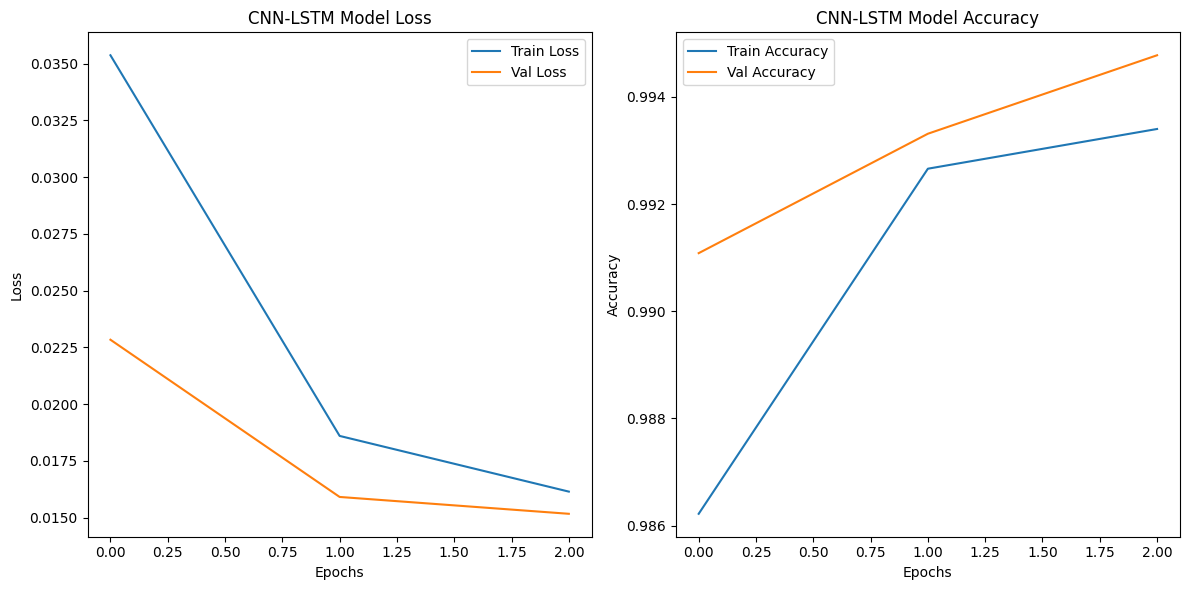

In [80]:
# ----- Plotting CNN-LSTM Loss and Accuracy -----
plt.figure(figsize=(12, 6))
# Loss
plt.subplot(1, 2, 1)
plt.plot(cnn_lstm_history.history['loss'], label='Train Loss')
plt.plot(cnn_lstm_history.history['val_loss'], label='Val Loss')
plt.title('CNN-LSTM Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(cnn_lstm_history.history['accuracy'], label='Train Accuracy')
plt.plot(cnn_lstm_history.history['val_accuracy'], label='Val Accuracy')
plt.title('CNN-LSTM Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

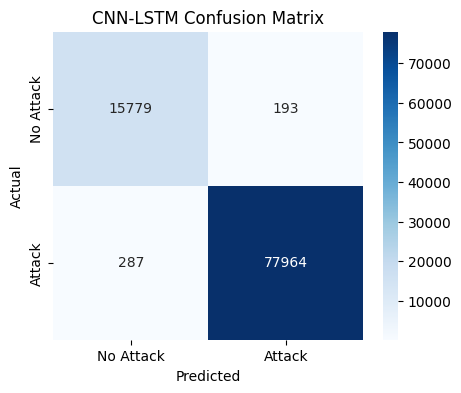

CNN-LSTM Model Metrics:
Accuracy: 0.9949
Precision: 0.9975
Recall: 0.9963
F1 Score: 0.9969


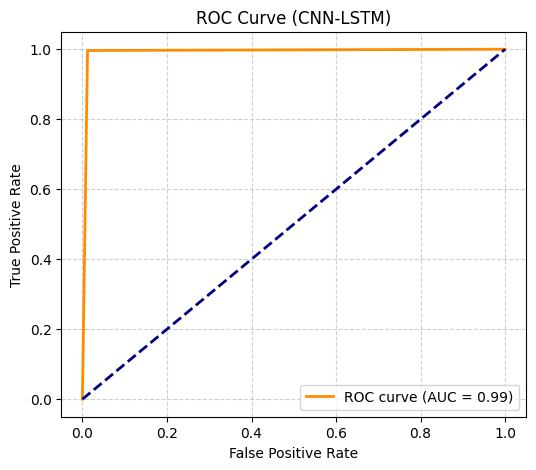

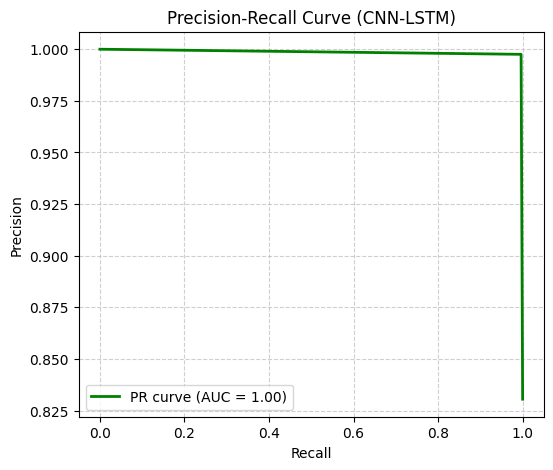

In [81]:
# ----- CNN-LSTM Metrics and Confusion Matrix ----- #
cnn_lstm_cm = confusion_matrix(y_test, cnn_lstm_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cnn_lstm_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title("CNN-LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ----- Print metrics ----- #
print("CNN-LSTM Model Metrics:")
print(f"Accuracy: {cnn_lstm_accuracy:.4f}")
print(f"Precision: {cnn_lstm_precision:.4f}")
print(f"Recall: {cnn_lstm_recall:.4f}")
print(f"F1 Score: {cnn_lstm_f1:.4f}")

# ----- ROC Curve and AUC ----- #
# cnn_lstm_y_prob = cnn_lstm_model.predict(X_test_scaled).ravel()  # probabilities from sigmoid

fpr, tpr, _ = roc_curve(y_test, cnn_lstm_y_pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1],[0,1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (CNN-LSTM)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ----- Precision-Recall Curve and AUC ----- #
precision, recall, _ = precision_recall_curve(y_test, cnn_lstm_y_pred)
pr_auc = average_precision_score(y_test, cnn_lstm_y_pred)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (CNN-LSTM)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [82]:
# ----- Adjust latency estimates to include model inference time (CNN-LSTM) ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_cnn_lstm  # Based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_cnn_lstm"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_cnn_lstm = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_cnn_lstm"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_cnn_lstm"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_cnn_lstm.to_csv("latency_summary_with_model_cnn_lstm.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_cnn_lstm)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.058835
1       1  4.654047e+06     96.058835


## **12. AE-MLP**

In [83]:
# ----- Adjust latency estimates to include model inference time (CNN-LSTM) ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_cnn_lstm  # Based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_cnn_lstm"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_cnn_lstm = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_cnn_lstm"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_cnn_lstm"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_cnn_lstm.to_csv("latency_summary_with_model_cnn_lstm.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_cnn_lstm)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.058835
1       1  4.654047e+06     96.058835


In [84]:
# ----- Define Autoencoder Model -----#
input_dim = X_train.shape[1]  # Feature size (number of input features)

# Define Encoder
input_layer = tf.keras.layers.Input(shape=(input_dim,))
encoder = tf.keras.layers.Dense(128, activation='relu')(input_layer)
encoder = tf.keras.layers.Dense(64, activation='relu')(encoder)
latent_space = tf.keras.layers.Dense(32, activation='relu')(encoder)  # Compressed representation

# Define Decoder (not needed for classification, but for AE structure)
decoder = tf.keras.layers.Dense(64, activation='relu')(latent_space)
decoder = tf.keras.layers.Dense(128, activation='relu')(decoder)
decoded_output = tf.keras.layers.Dense(input_dim, activation='sigmoid')(decoder)

# Autoencoder model
autoencoder = tf.keras.models.Model(input_layer, decoded_output)

In [85]:
# Encoder model (used for feature extraction)
encoder_model = tf.keras.models.Model(input_layer, latent_space)

In [86]:
# ----- Compile and Train Autoencoder Model -----#
autoencoder.compile(optimizer='adam', loss='mean_squared_error')
autoencoder_history = autoencoder.fit(X_train_scaled, X_train_scaled, epochs=3, batch_size=32, validation_data=(X_val_scaled, X_val_scaled), verbose=1)

Epoch 1/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - loss: 0.0038 - val_loss: 6.5548e-05
Epoch 2/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - loss: 5.6577e-05 - val_loss: 3.9126e-05
Epoch 3/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - loss: 4.0227e-05 - val_loss: 3.1375e-05


In [87]:
# ----- Extract Latent Features using Encoder -----#
X_train_latent = encoder_model.predict(X_train_scaled)
X_val_latent = encoder_model.predict(X_val_scaled)
X_test_latent = encoder_model.predict(X_test_scaled)

13741/13741 ━━━━━━━━━━━━━━━━━━━━ 16s 1ms/step
2945/2945 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
2945/2945 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step


In [88]:
# ----- Define MLP Model using Latent Features -----#
ae_mlp_model = tf.keras.Sequential([
    tf.keras.layers.InputLayer(input_shape=(X_train_latent.shape[1],)),  # Shape of the latent space
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


In [89]:
# ----- Compile MLP Model -----#
ae_mlp_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [90]:
# ----- Train MLP Model -----#
start_time = time.time()
ae_mlp_history = ae_mlp_model.fit(
    X_train_latent, y_train,
    epochs=3,
    batch_size=32,
    validation_data=(X_val_latent, y_val),
    verbose=1
)
fit_time_ae_mlp = (time.time() - start_time) * 1000  # convert seconds → ms

print(f"AE-MLP fit time: {fit_time_ae_mlp:.2f} ms")

Epoch 1/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 36s 2ms/step - accuracy: 0.9929 - loss: 0.0207 - val_accuracy: 0.9992 - val_loss: 0.0034
Epoch 2/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - accuracy: 0.9994 - loss: 0.0023 - val_accuracy: 0.9997 - val_loss: 0.0016
Epoch 3/3
13741/13741 ━━━━━━━━━━━━━━━━━━━━ 34s 2ms/step - accuracy: 0.9994 - loss: 0.0020 - val_accuracy: 0.9995 - val_loss: 0.0020
AE-MLP fit time: 102343.71 ms


In [91]:
# ----- Get Predictions and Metrics for AE-MLP -----#
ae_mlp_y_pred = (ae_mlp_model.predict(X_test_latent) > 0.5).astype("int32")
ae_mlp_accuracy = accuracy_score(y_test, ae_mlp_y_pred)
ae_mlp_precision = precision_score(y_test, ae_mlp_y_pred)
ae_mlp_recall = recall_score(y_test, ae_mlp_y_pred)
ae_mlp_f1 = f1_score(y_test, ae_mlp_y_pred)

# ----- Measure inference time per sample (in ms) -----#
import time
start_time = time.time()
_ = ae_mlp_model.predict(X_test_latent)
total_inf_time = time.time() - start_time
model_inf_time_ae_mlp = (total_inf_time / len(X_test_latent)) * 1000  # convert seconds → ms

print(f"AE-MLP inference time per sample: {model_inf_time_ae_mlp:.6f} ms")


2945/2945 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
2945/2945 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
AE-MLP inference time per sample: 0.048066 ms


In [92]:
# ----- Get Predictions and Metrics for MLP (Train) -----#
ae_mlp_y_pred_train = (ae_mlp_model.predict(X_train_latent) > 0.5).astype("int32")
ae_mlp_accuracy_train = accuracy_score(y_train, ae_mlp_y_pred_train)
ae_mlp_precision_train = precision_score(y_train, ae_mlp_y_pred_train)
ae_mlp_recall_train = recall_score(y_train, ae_mlp_y_pred_train)
ae_mlp_f1_train = f1_score(y_train, ae_mlp_y_pred_train)


13741/13741 ━━━━━━━━━━━━━━━━━━━━ 16s 1ms/step


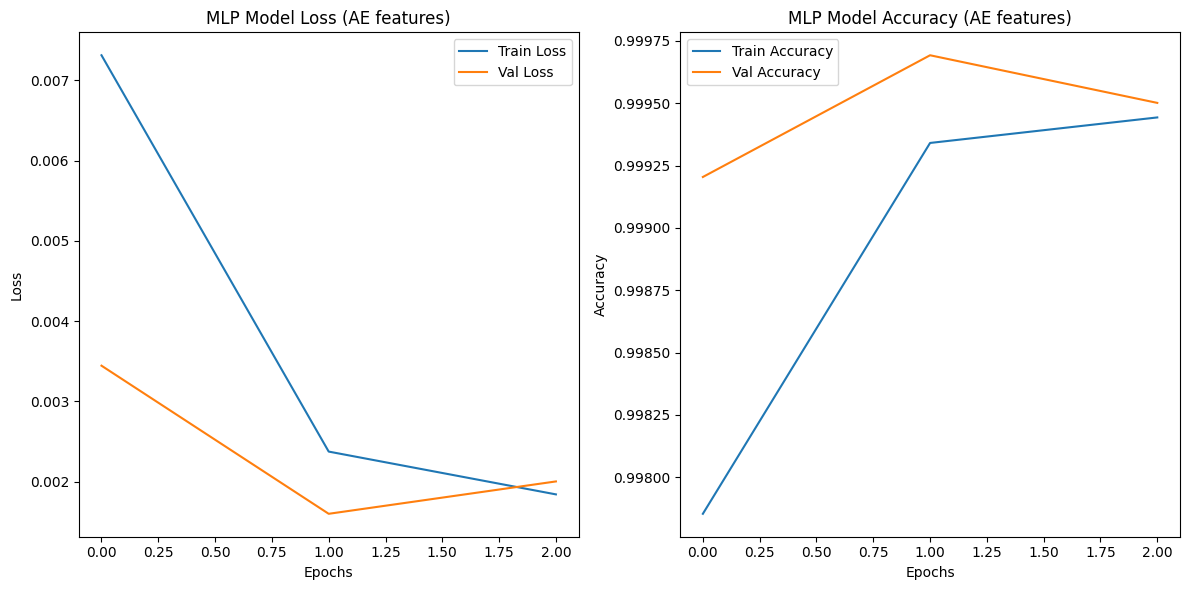

In [93]:
# ----- Plotting Loss and Accuracy -----#
plt.figure(figsize=(12, 6))
# Loss
plt.subplot(1, 2, 1)
plt.plot(ae_mlp_history.history['loss'], label='Train Loss')
plt.plot(ae_mlp_history.history['val_loss'], label='Val Loss')
plt.title('MLP Model Loss (AE features)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(ae_mlp_history.history['accuracy'], label='Train Accuracy')
plt.plot(ae_mlp_history.history['val_accuracy'], label='Val Accuracy')
plt.title('MLP Model Accuracy (AE features)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

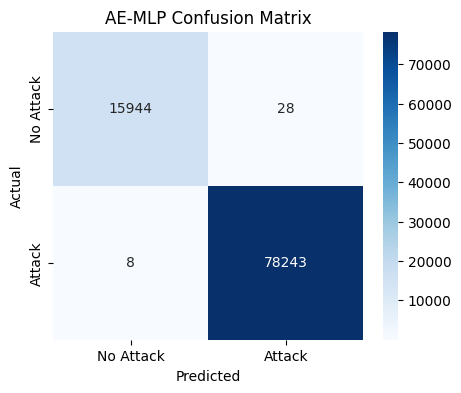

Accuracy (AE-MLP): 99.97%
Precision (AE-MLP): 99.97%
Recall (AE-MLP): 99.99%
F1 Score (AE-MLP): 99.98%


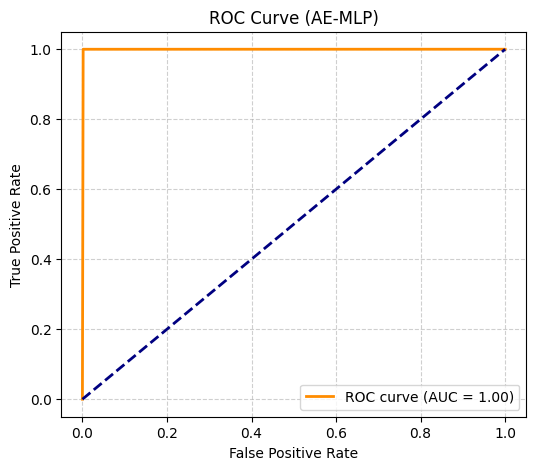

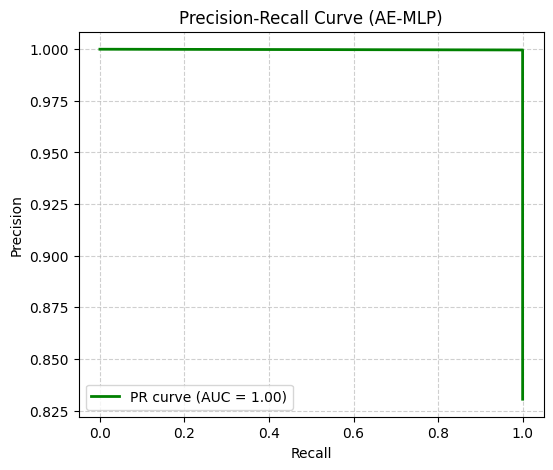

In [94]:
# ----- Confusion Matrix for AE-MLP ----- #
ae_mlp_cm = confusion_matrix(y_test, ae_mlp_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(ae_mlp_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['No Attack', 'Attack'], yticklabels=['No Attack', 'Attack'])
plt.title("AE-MLP Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ----- Print metrics ----- #
print(f'Accuracy (AE-MLP): {mlp_accuracy * 100:.2f}%')
print(f'Precision (AE-MLP): {mlp_precision * 100:.2f}%')
print(f'Recall (AE-MLP): {mlp_recall * 100:.2f}%')
print(f'F1 Score (AE-MLP): {mlp_f1 * 100:.2f}%')

# ----- ROC Curve and AUC ----- #
# ae_mlp_y_prob = ae_mlp_model.predict(X_test_scaled).ravel()  # probabilities from sigmoid

fpr, tpr, _ = roc_curve(y_test, ae_mlp_y_pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1],[0,1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (AE-MLP)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ----- Precision-Recall Curve and AUC ----- #
precision, recall, _ = precision_recall_curve(y_test, ae_mlp_y_pred)
pr_auc = average_precision_score(y_test, ae_mlp_y_pred)

plt.figure(figsize=(6,5))
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (AE-MLP)')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [95]:
# ----- Adjust latency estimates to include model inference time (AE-MLP) ----- #
MODEL_INFERENCE_TIME_MS = model_inf_time_ae_mlp  # Based on measured model inference time (per sample)

# Add model inference time to estimated latency
df["Estimated_Latency_WithModel_ms_ae_mlp"] = df["Estimated_Latency_ms"] + MODEL_INFERENCE_TIME_MS

# ----- Summarize latency (with model) by class ----- #
lat_summary_with_ae_mlp = (
    df.dropna(subset=["Estimated_Latency_WithModel_ms_ae_mlp"])
      .groupby(" Label")["Estimated_Latency_WithModel_ms_ae_mlp"]
      .agg(
          mean_ms="mean",
          median_ms="median"
      )
      .reset_index()
)

# ----- Save summarized latency results to CSV ----- #
lat_summary_with_ae_mlp.to_csv("latency_summary_with_model_ae_mlp.csv", index=False)

# Optional: print for quick inspection
print(lat_summary_with_ae_mlp)


    Label       mean_ms     median_ms
0       0  1.107659e+07  27924.048066
1       1  4.654047e+06     96.048066


## **Comparison of training time and inference time**

In [96]:
import pandas as pd

data = {
    "Model Name": [
        "Random Forest",
        "Decision Tree",
        "SVM",
        "Gradient Boosting",
        "AdaBoost",
        "MLP",
        "LSTM",
        "BiLSTM",
        "CNN-LSTM",
        "AE-MLP"
    ],
    "Training Time (ms)": [
        fit_time_rf,
        fit_time_dt,
        fit_time_svm,
        fit_time_gb,
        fit_time_ab,
        fit_time_mlp,
        fit_time_lstm,
        fit_time_bilstm,
        fit_time_cnn_lstm,
        fit_time_ae_mlp
    ],
    "Inference Time per Sample (ms)": [
        model_inf_time_rf,
        model_inf_time_dt,
        model_inf_time_svm,
        model_inf_time_gb,
        model_inf_time_ab,
        model_inf_time_mlp,
        model_inf_time_lstm,
        model_inf_time_bilstm,
        model_inf_time_cnn_lstm,
        model_inf_time_ae_mlp
    ]
}

comparison_df = pd.DataFrame(data)
print(comparison_df.to_string(index=False))


       Model Name  Training Time (ms)  Inference Time per Sample (ms)
    Random Forest            1.014041                        0.000312
    Decision Tree          384.836912                        0.000141
              SVM         5159.090042                        0.014394
Gradient Boosting         8014.468193                        0.000364
         AdaBoost        10736.399651                        0.001956
              MLP       105892.198563                        0.049622
             LSTM       730370.253563                        0.153250
           BiLSTM       948784.400702                        0.284813
         CNN-LSTM       164062.096596                        0.058835
           AE-MLP       102343.712807                        0.048066


## **Comparison of results**

In [97]:
# ----- Creating a DataFrame for the results (Train) -----#
results_train = {
    "Model": ["Random Forest", "SVM", "Decision Tree", "GBoost", "AdaBoost",
              "MLP", "LSTM", "BiLSTM", "CNN-LSTM", "AE-MLP"],
    "Accuracy_train": [rf_accuracy_train, svm_accuracy_train, dt_accuracy_train, gboost_accuracy_train, adaboost_accuracy_train,
                       mlp_accuracy_train, lstm_accuracy_train, bilstm_accuracy_train, cnn_lstm_accuracy_train, ae_mlp_accuracy_train],
    "Precision_train": [rf_precision_train, svm_precision_train, dt_precision_train, gboost_precision_train, adaboost_precision_train,
                        mlp_precision_train, lstm_precision_train, bilstm_precision_train, cnn_lstm_precision_train, ae_mlp_precision_train],
    "Recall_train": [rf_recall_train, svm_recall_train, dt_recall_train, gboost_recall_train, adaboost_recall_train,
                     mlp_recall_train, lstm_recall_train, bilstm_recall_train, cnn_lstm_recall_train, ae_mlp_recall_train],
    "F1 Score_train": [rf_f1_train, svm_f1_train, dt_f1_train, gboost_f1_train, adaboost_f1_train,
                       mlp_f1_train, lstm_f1_train, bilstm_f1_train, cnn_lstm_f1_train, ae_mlp_f1_train]
}


In [98]:
# ----- Convert the dictionary to a pandas DataFrame -----#
metrics_df_train = pd.DataFrame(results_train)

# ------ Set the Model column as the index ------#
metrics_df_train.set_index("Model", inplace=True)

# ------ Display the table -----#
metrics_df_train

,Accuracy_train,Precision_train,Recall_train,F1 Score_train
Model,,,,
Random Forest,0.953239,0.950204,0.995884,0.972508
SVM,0.991613,0.998247,0.991642,0.994934
Decision Tree,0.989770,0.998232,0.989435,0.993814
GBoost,0.964938,0.963130,0.995906,0.979244
AdaBoost,0.963491,0.963496,0.993688,0.978359
MLP,0.999627,0.999715,0.999836,0.999775
LSTM,0.991324,0.998139,0.991401,0.994759
BiLSTM,0.982472,0.989754,0.989134,0.989444
CNN-LSTM,0.995231,0.997784,0.996470,0.997127


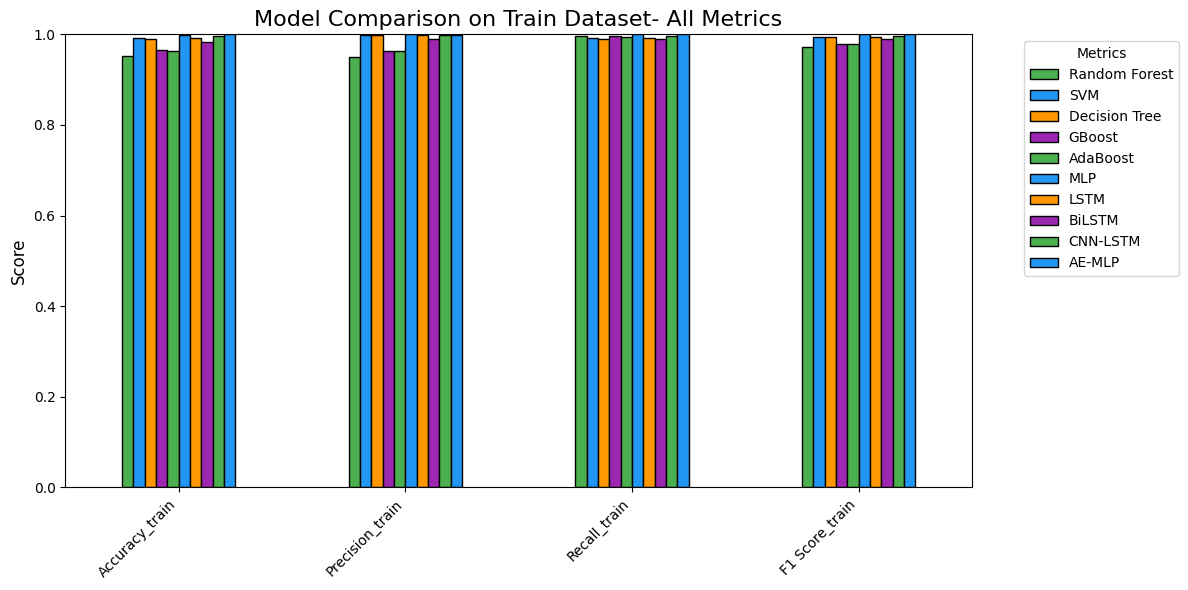

In [99]:
# ----- Plot a grouped bar plot for all metrics with more contrast -----#
metrics_df_train.T.plot(kind='bar', figsize=(12, 6), edgecolor='black',
                  color=['#4CAF50', '#2196F3', '#FF9800', '#9C27B0'])
plt.title("Model Comparison on Train Dataset- All Metrics", fontsize=16)
plt.ylabel("Score", fontsize=12)
plt.ylim(0, 1)  # Set y-axis scale to 0-1 for better visibility of differences
plt.xticks(rotation=45, ha='right', fontsize=10)  # Rotate x-axis labels to make them readable
plt.legend(title="Metrics", bbox_to_anchor=(1.05, 1), loc='upper left')  # Place legend outside the plot
plt.tight_layout()
plt.show()

In [100]:
# ----- Creating a DataFrame for the results -----#
results = {
    "Model": ["Random Forest", "SVM", "Decision Tree", "GBoost", "AdaBoost",
              "K-Means", "DBSCAN","MLP", "LSTM", "BiLSTM", "CNN-LSTM", "AE-MLP"],
    "Accuracy": [rf_accuracy, svm_accuracy, dt_accuracy, gboost_accuracy, adaboost_accuracy,
                 kmeans_accuracy, dbscan_accuracy,mlp_accuracy, lstm_accuracy, bilstm_accuracy, cnn_lstm_accuracy, ae_mlp_accuracy],
    "Precision": [rf_precision, svm_precision, dt_precision, gboost_precision, adaboost_precision,
                  kmeans_precision, dbscan_precision,mlp_precision, lstm_precision, bilstm_precision, cnn_lstm_precision, ae_mlp_precision],
    "Recall": [rf_recall, svm_recall, dt_recall, gboost_recall, adaboost_recall,
               kmeans_recall, dbscan_recall,mlp_recall, lstm_recall, bilstm_recall, cnn_lstm_recall, ae_mlp_recall],
    "F1 Score": [rf_f1, svm_f1, dt_f1, gboost_f1, adaboost_f1,
                 kmeans_f1, dbscan_f1,mlp_f1, lstm_f1, bilstm_f1, cnn_lstm_f1, ae_mlp_f1]
}


In [101]:
# ----- Convert the dictionary to a pandas DataFrame -----#
metrics_df = pd.DataFrame(results)

# ------ Set the Model column as the index ------#
metrics_df.set_index("Model", inplace=True)

# ------ Display the table -----#
metrics_df

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Random Forest,0.952623,0.949718,0.995668,0.972150
SVM,0.991350,0.998237,0.991336,0.994774
Decision Tree,0.989429,0.998259,0.988997,0.993606
GBoost,0.964478,0.962827,0.995668,0.978972
AdaBoost,0.962928,0.963185,0.993329,0.978025
K-Means,0.830490,0.830490,1.000000,0.907396
DBSCAN,0.996589,0.998655,0.997231,0.997943
MLP,0.999682,0.999744,0.999872,0.999808
LSTM,0.991127,0.998172,0.991131,0.994639


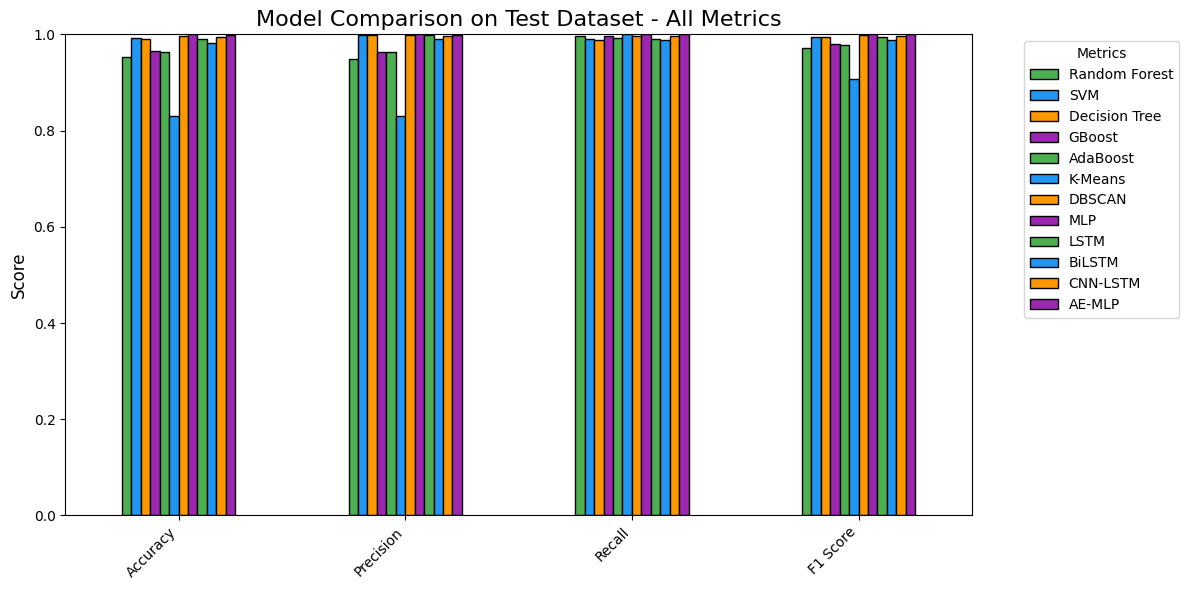

In [102]:
# ----- Plot a grouped bar plot for all metrics with more contrast -----#
metrics_df.T.plot(kind='bar', figsize=(12, 6), edgecolor='black',
                  color=['#4CAF50', '#2196F3', '#FF9800', '#9C27B0'])
plt.title("Model Comparison on Test Dataset - All Metrics", fontsize=16)
plt.ylabel("Score", fontsize=12)
plt.ylim(0, 1)  # Set y-axis scale to 0-1 for better visibility of differences
plt.xticks(rotation=45, ha='right', fontsize=10)  # Rotate x-axis labels to make them readable
plt.legend(title="Metrics", bbox_to_anchor=(1.05, 1), loc='upper left')  # Place legend outside the plot
plt.tight_layout()
plt.show()